# **Changing the Last Row: Projective Transformations (Homographies) and Panorama Stitching**

In the previous class we studied **affine transformations**: in homogeneous coordinates, $3 \times 3$
matrices whose last row is fixed to $[0 \;\; 0 \;\; 1]$. We implemented image warping with forward and
backward mapping, and used OpenCV's `cv2.warpAffine`. In this notebook we change the one part we have kept
fixed so far, **the last row**, and see where this leads: perspective, vanishing points and the horizon,
the pinhole camera, and homographies in OpenCV.

In the second part we turn the question around: given two **photos** of the same scene, how do we find
the homography between them? We see when such a homography exists, estimate it from point
correspondences (the **DLT** algorithm with **data normalization**), make the estimation robust with
**RANSAC**, and stitch two photos into a **panorama**.

## Table of Contents
1. Setup
2. Recap: Affine Transformations and Image Warping
3. Changing the Last Row
4. Points at Infinity, Vanishing Points and the Horizon
5. Where Does Such a Matrix Come From? A Camera Looking at a Plane
6. Homographies in OpenCV
7. Try It Yourself (Interactive)
8. When Are Two Photos Related by a Homography?
9. Estimating a Homography: the DLT Algorithm
10. Data Normalization
11. Panorama Stitching
12. Automatic Correspondences: Feature Matching and RANSAC
13. Summary

---

## 1. Setup

We use NumPy, OpenCV and Matplotlib. Images are displayed with Matplotlib, which works both in Google
Colab and in plain Jupyter. Remember that OpenCV stores color images as **BGR**, so `show_images`
converts them to RGB before plotting. The axes show pixel coordinates, which helps to see where things
move.

**Coordinate convention.** Throughout the notebook we use *image coordinates*:

- $x$ points to the right (column index), $y$ points **down** (row index), the origin is the
  center of the **top-left** pixel;
- NumPy indexes images as `img[y, x]` (row first!), while OpenCV's geometric functions take points as
  `(x, y)` and image sizes as `(width, height)`;
- because $y$ points down, a rotation by a *positive* angle with the usual rotation matrix appears
  **clockwise** on the screen.

In [ ]:
import math
import os
import time
import urllib.request
import zipfile

import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

np.set_printoptions(precision=4, suppress=True)


def to_rgb(img):
    """OpenCV stores color images as BGR, Matplotlib expects RGB."""
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img.ndim == 3 else img


def show_images(images, titles=None, cols=None, size=3.5):
    """Show BGR (or grayscale) images side by side, with pixel coordinates on the axes."""
    cols = cols or len(images)
    rows = int(np.ceil(len(images) / cols))
    aspect = max(im.shape[0] / im.shape[1] for im in images)
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * aspect * rows + 0.5 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for i, im in enumerate(images):
        ax = axes.ravel()[i]
        ax.axis('on')
        ax.imshow(to_rgb(im), cmap='gray' if im.ndim == 2 else None, interpolation='nearest')
        if titles is not None:
            ax.set_title(titles[i], fontsize=10)
    plt.tight_layout()
    plt.show()

width = 250, height = 375   (NumPy shape: (375, 250, 3))


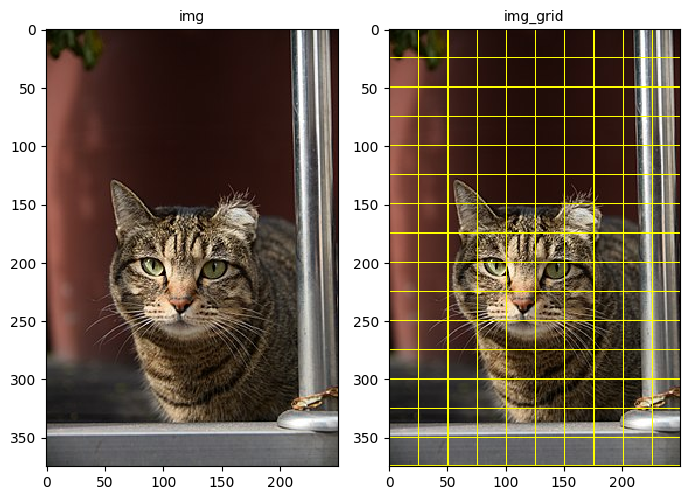

In [ ]:
IMG_URL = 'https://cv.inf.elte.hu/wp-content/uploads/2026/02/cat.jpg'
IMG_PATH = 'cat.jpg'

if not os.path.exists(IMG_PATH):
    urllib.request.urlretrieve(IMG_URL, IMG_PATH)

img = cv2.imread(IMG_PATH)
height, width = img.shape[:2]
print(f'width = {width}, height = {height}   (NumPy shape: {img.shape})')


def draw_grid(img, step=25, color=(0, 255, 255)):
    """Copy of the image with a yellow grid every `step` pixels: makes straight lines and parallelism visible."""
    out = img.copy()
    h, w = img.shape[:2]
    for x in list(range(0, w, step)) + [w - 1]:
        cv2.line(out, (x, 0), (x, h - 1), color, 1)
    for y in list(range(0, h, step)) + [h - 1]:
        cv2.line(out, (0, y), (w - 1, y), color, 1)
    return out


img_grid = draw_grid(img)
show_images([img, img_grid], ['img', 'img_grid'])

## 2. Recap: Affine Transformations and Image Warping

**Homogeneous coordinates.** We append a $1$ to every point, $(x, y) \mapsto (x, y, 1)$. An affine
transformation $\mathbf{x}' = A\mathbf{x} + \mathbf{t}$ is then a single $3 \times 3$ matrix:
$$
T = \begin{bmatrix} A & \mathbf{t} \\ \mathbf{0}^\top & 1 \end{bmatrix}
  = \begin{bmatrix} a_{11} & a_{12} & t_x \\ a_{21} & a_{22} & t_y \\ 0 & 0 & 1 \end{bmatrix},
\qquad
T \begin{bmatrix} \mathbf{x} \\ 1 \end{bmatrix} = \begin{bmatrix} A\mathbf{x} + \mathbf{t} \\ 1 \end{bmatrix}.
$$
- The last row $[0 \;\; 0 \;\; 1]$ keeps the third coordinate at $1$.
- Composition is matrix multiplication, read **right to left**. For example, a rotation about the point
  $\mathbf{c}$ is $T(\mathbf{c})\, R(\alpha)\, T(-\mathbf{c})$.
- A **direction** $(d_x, d_y)$ gets a $0$ as third coordinate, so translations do not affect it. We will
  need this for vanishing points.
- Affine maps preserve straight lines, parallelism, ratios of lengths along a line and ratios of areas.
  They have 6 degrees of freedom, so 3 point correspondences determine them (`cv2.getAffineTransform`).

The helper functions from the previous class, unchanged:

In [ ]:
def translation(tx, ty):
    return np.array([[1, 0, tx],
                     [0, 1, ty],
                     [0, 0, 1]], dtype=float)


def rotation(angle_deg):
    a = np.deg2rad(angle_deg)
    return np.array([[np.cos(a), -np.sin(a), 0],
                     [np.sin(a),  np.cos(a), 0],
                     [0,          0,         1]])


def scaling(sx, sy):
    return np.array([[sx, 0,  0],
                     [0,  sy, 0],
                     [0,  0,  1]], dtype=float)


def shear(k):
    return np.array([[1, k, 0],
                     [0, 1, 0],
                     [0, 0, 1]], dtype=float)


p = np.array([10, 20, 1])      # a point
d = np.array([1, 0, 0])        # a direction
T = translation(100, 50)
print('T @ p =', T @ p, '  -> the point moved')
print('T @ d =', T @ d, '  -> the direction did not')

T @ p = [110.  70.   1.]   -> the point moved
T @ d = [1. 0. 0.]   -> the direction did not


**Image warping.**
- **Forward mapping** sends every source pixel to its rounded position in the output. Because the
  transformed source grid has a different density than the output grid (areas are scaled by $|\det A|$), it
  leaves **holes** where the image is enlarged and causes **collisions** where it is shrunk.
- **Backward mapping** goes over the output pixels, maps each one back with $T^{-1}$ and interpolates the
  source there. Every output pixel is visited exactly once. This is what OpenCV does:
  `cv2.warpAffine(src, M, dsize)`, where `M` is the top two rows of $T$ and `dsize` is (width, height).

`forward_warp` and `backward_warp` from the previous class, unchanged. Note that both already **divide by the
third coordinate** of the transformed points. For an affine $T$ it was always $1$, so this did nothing. Now
it will matter.

In [ ]:
def forward_warp(img, T, out_size=None):
    """Forward mapping: send every SOURCE pixel to its (rounded) position in the output.

    T: 3x3 matrix mapping source coordinates (x, y, 1) to output coordinates.
    out_size: (width, height) of the output, defaults to the size of the input.
    Returns the output image and `hits`: how many source pixels landed on each output pixel.
    """
    h, w = img.shape[:2]
    out_w, out_h = out_size if out_size is not None else (w, h)

    # homogeneous coordinates of all source pixels, one column per pixel (x = column, y = row)
    ys, xs = np.mgrid[0:h, 0:w]
    src = np.stack([xs.ravel(), ys.ravel(), np.ones(h * w)])

    dst = T @ src
    with np.errstate(divide='ignore', invalid='ignore'):
        xd = np.floor(dst[0] / dst[2] + 0.5)          # divide by the 3rd coordinate, round to the nearest pixel
        yd = np.floor(dst[1] / dst[2] + 0.5)
    valid = (xd >= 0) & (xd < out_w) & (yd >= 0) & (yd < out_h)
    xd, yd = xd[valid].astype(int), yd[valid].astype(int)

    out = np.zeros((out_h, out_w) + img.shape[2:], dtype=img.dtype)
    out[yd, xd] = img[ys.ravel()[valid], xs.ravel()[valid]]   # several pixels on the same spot: one of them wins

    hits = np.zeros((out_h, out_w), dtype=int)
    np.add.at(hits, (yd, xd), 1)
    return out, hits

In [ ]:
def backward_warp(img, T, out_size=None, interpolation='bilinear'):
    """Backward (inverse) mapping: for every OUTPUT pixel, look up where it comes from in the source.

    T: 3x3 matrix mapping source to output coordinates (the same T as in forward_warp; we invert it here).
    out_size: (width, height) of the output, defaults to the size of the input.
    interpolation: 'nearest' or 'bilinear'. Output pixels whose preimage is outside the source stay black.
    """
    h, w = img.shape[:2]
    out_w, out_h = out_size if out_size is not None else (w, h)

    # homogeneous coordinates of all OUTPUT pixels
    ys, xs = np.mgrid[0:out_h, 0:out_w]
    dst = np.stack([xs.ravel(), ys.ravel(), np.ones(out_h * out_w)])

    src = np.linalg.inv(T) @ dst
    with np.errstate(divide='ignore', invalid='ignore'):
        x, y = src[0] / src[2], src[1] / src[2]       # real-valued source positions

    out = np.zeros((out_h * out_w,) + img.shape[2:], dtype=img.dtype)
    if interpolation == 'nearest':
        xi, yi = np.floor(x + 0.5), np.floor(y + 0.5)
        valid = (xi >= 0) & (xi < w) & (yi >= 0) & (yi < h)
        out[valid] = img[yi[valid].astype(int), xi[valid].astype(int)]
    elif interpolation == 'bilinear':
        valid = (x >= 0) & (x <= w - 1) & (y >= 0) & (y <= h - 1)
        x, y = x[valid], y[valid]
        x0 = np.minimum(np.floor(x).astype(int), w - 2)  # top-left neighbor (kept inside the image)
        y0 = np.minimum(np.floor(y).astype(int), h - 2)
        ax, ay = x - x0, y - y0                          # fractional offsets in [0, 1]
        if img.ndim == 3:                                # broadcast the weights over the color channels
            ax, ay = ax[:, None], ay[:, None]
        I = img.astype(float)
        value = ((1 - ax) * (1 - ay) * I[y0, x0]     + ax * (1 - ay) * I[y0, x0 + 1] +
                 (1 - ax) * ay       * I[y0 + 1, x0] + ax * ay       * I[y0 + 1, x0 + 1])
        out[valid] = np.clip(np.round(value), 0, 255).astype(img.dtype)   # assumes an 8-bit image
    else:
        raise ValueError(interpolation)
    return out.reshape((out_h, out_w) + img.shape[2:])

`target_region` finds the output pixels that lie inside the transformed image, and `coverage_image` marks
holes and collisions of the forward mapping (also from the previous class):

In [ ]:
def target_region(T, src_size, out_size, margin=0.5):
    """Output pixels whose preimage T^-1 (x, y) lies inside the source image (with a margin of half a pixel)."""
    (w, h), (out_w, out_h) = src_size, out_size
    ys, xs = np.mgrid[0:out_h, 0:out_w]
    src = np.linalg.inv(T) @ np.stack([xs.ravel(), ys.ravel(), np.ones(out_h * out_w)])
    with np.errstate(divide='ignore', invalid='ignore'):
        x, y = src[0] / src[2], src[1] / src[2]
    inside = (x >= -margin) & (x < w - 1 + margin) & (y >= -margin) & (y < h - 1 + margin)
    return inside.reshape(out_h, out_w)


COVERAGE_CMAP = ListedColormap(['white', '#d62728', '#d9d9d9', '#2a78d6'])
COVERAGE_LEGEND = [Patch(color='#d62728', label='hole (0 source pixels)'),
                   Patch(color='#d9d9d9', label='exactly 1 source pixel'),
                   Patch(color='#2a78d6', label='collision (2+ source pixels)')]


def coverage_image(hits, region):
    """0: outside the image, 1: hole, 2: exactly one source pixel, 3: collision."""
    cov = np.zeros(hits.shape, dtype=int)
    cov[region & (hits == 0)] = 1
    cov[hits == 1] = 2
    cov[hits > 1] = 3
    return cov

As a reminder of what affine maps do, we apply one (a scaling, a shear and a rotation about the image center)
to the image with the grid, both with our `backward_warp` and with `cv2.warpAffine`:

T_aff =
 [[ 0.6578  0.0895 25.8733]
 [ 0.2394  0.7775 11.802 ]
 [ 0.      0.      1.    ]]


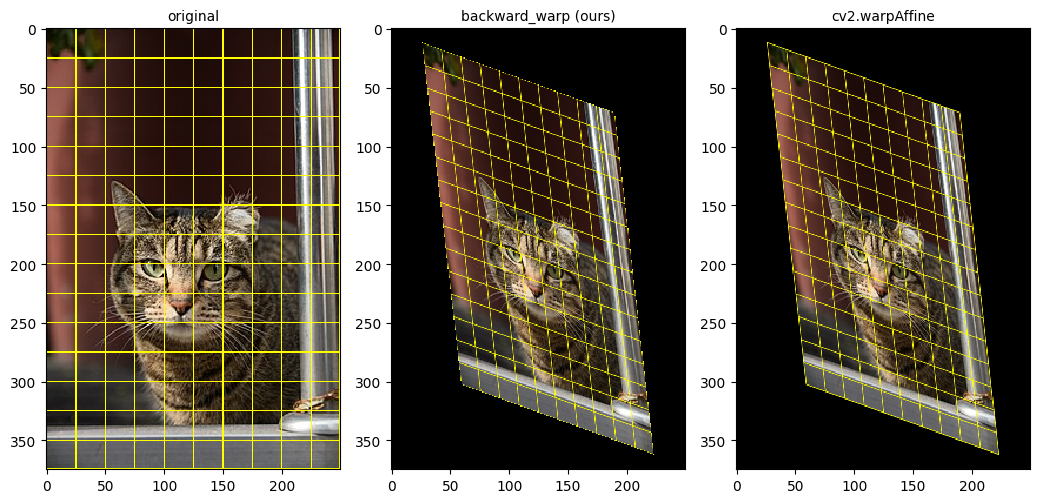

In [ ]:
cx, cy = (width - 1) / 2, (height - 1) / 2         # image center (pixel centers are at integer coordinates)
T_aff = translation(cx, cy) @ rotation(20) @ shear(0.5) @ scaling(0.7, 0.7) @ translation(-cx, -cy)
print('T_aff =\n', T_aff)

show_images([img_grid, backward_warp(img_grid, T_aff), cv2.warpAffine(img_grid, T_aff[:2], (width, height))],
            ['original', 'backward_warp (ours)', 'cv2.warpAffine'])

Straight lines stay straight, parallel lines stay parallel, and all grid cells are identical parallelograms.
Keep this picture in mind.

---

## 3. Changing the Last Row

So far the last row of $T$ was always $[0 \;\; 0 \;\; 1]$. What happens if we change it? Let
$$
H = \begin{bmatrix} h_{11} & h_{12} & h_{13} \\ h_{21} & h_{22} & h_{23} \\ h_{31} & h_{32} & h_{33} \end{bmatrix},
\qquad
\begin{bmatrix} u \\ v \\ w \end{bmatrix} = H \begin{bmatrix} x \\ y \\ 1 \end{bmatrix}.
$$
The third coordinate $w = h_{31} x + h_{32} y + h_{33}$ is no longer $1$. To get back a 2D point, we divide
by it. This is the **perspective division**:
$$
x' = \frac{u}{w} = \frac{h_{11} x + h_{12} y + h_{13}}{h_{31} x + h_{32} y + h_{33}}, \qquad
y' = \frac{v}{w} = \frac{h_{21} x + h_{22} y + h_{23}}{h_{31} x + h_{32} y + h_{33}}.
$$

This is how homogeneous coordinates are defined in general: $(u, v, w)$ and $(\lambda u, \lambda v, \lambda w)$
represent the **same** 2D point $(u/w, v/w)$ for any $\lambda \neq 0$. Geometrically, a homogeneous vector is a
ray through the origin of 3D space, and the 2D point is where this ray pierces the plane $w = 1$.

Such an $H$ (invertible) is a **projective transformation**, or **homography**. Our `forward_warp` and
`backward_warp` already divide by the third coordinate, so they work unchanged.

**Careful:** `cv2.warpAffine` only takes the top two rows and silently assumes $[0 \;\; 0 \;\; 1]$ as the
last row. For a general $H$ we need `cv2.warpPerspective` (Section 6).

### 3.1 Changing $h_{33}$: the scale of homogeneous coordinates
With $H = \mathrm{diag}(1, 1, h_{33})$ we get $x' = x / h_{33}$, $y' = y / h_{33}$: a uniform scaling by
$1/h_{33}$ about the origin. Indeed, $\mathrm{diag}(1, 1, 2) = 2 \cdot \mathrm{diag}(0.5, 0.5, 1)$, and
multiplying $H$ by a non-zero number does not change the transformation. Hence:

> $H$ and $\lambda H$ describe the same transformation, so a $3 \times 3$ homography has only
> **8 degrees of freedom**, not 9. We usually normalize it so that $h_{33} = 1$ (or $\|H\| = 1$).

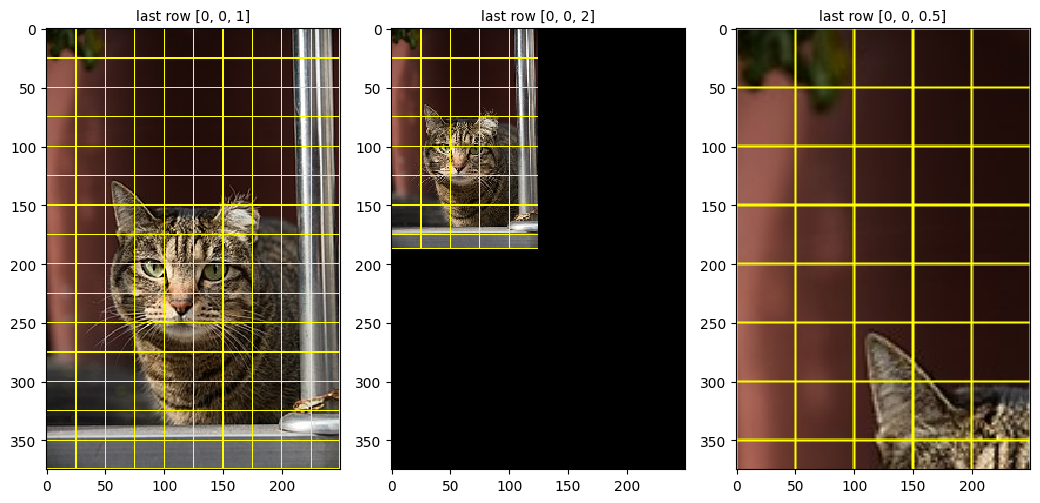

diag(1, 1, 2) gives exactly the same image as scaling(0.5, 0.5): True


In [ ]:
show_images([backward_warp(img_grid, np.diag([1.0, 1.0, h33])) for h33 in (1, 2, 0.5)],
            [f'last row [0, 0, {h33}]' for h33 in (1, 2, 0.5)])

same = np.array_equal(backward_warp(img, np.diag([1.0, 1.0, 2.0])), backward_warp(img, scaling(0.5, 0.5)))
print('diag(1, 1, 2) gives exactly the same image as scaling(0.5, 0.5):', same)

### 3.2 Changing $h_{31}$ and $h_{32}$: perspective
Now let the last row be $[h_{31} \;\; h_{32} \;\; 1]$, with the rest of $H$ the identity. Then
$$
w = 1 + h_{31} x + h_{32} y
$$
**varies across the image**: where $w > 1$ the image is shrunk, where $w < 1$ it is enlarged. One side
appears farther away and the other closer, as if the image plane were tilted. $h_{31}$ acts along $x$,
$h_{32}$ along $y$. Since the image coordinates go up to a few hundred pixels, already values around
$0.001$ have a strong effect. The last example combines both: $h_{31} = 0.001$, $h_{32} = 0.002$.

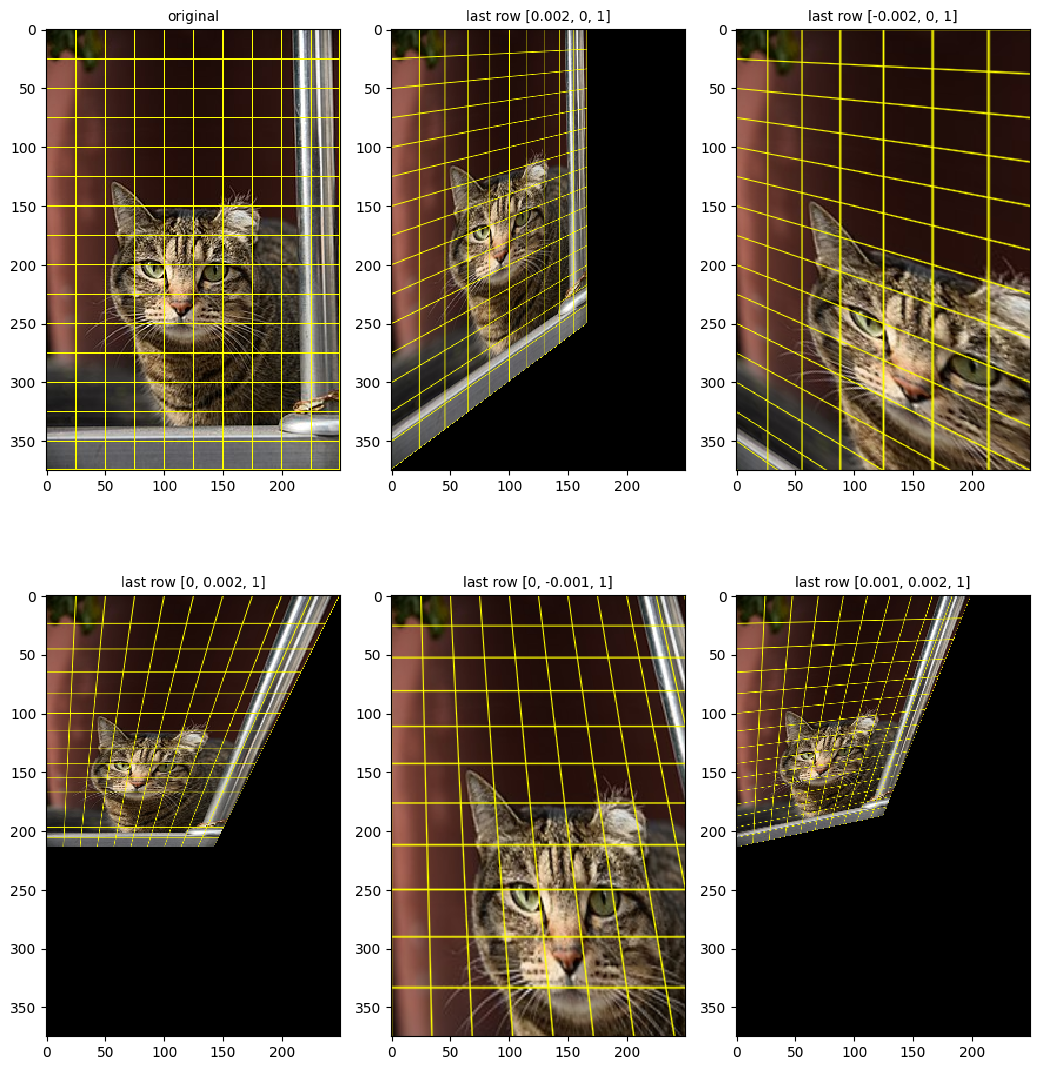

In [ ]:
def last_row_matrix(h31, h32, h33=1.0):
    """Identity matrix with the last row replaced by [h31, h32, h33]."""
    return np.array([[1, 0, 0],
                     [0, 1, 0],
                     [h31, h32, h33]], dtype=float)


last_rows = [(0.002, 0), (-0.002, 0), (0, 0.002), (0, -0.001), (0.001, 0.002)]
show_images([img_grid] + [backward_warp(img_grid, last_row_matrix(h31, h32)) for h31, h32 in last_rows],
            ['original'] + [f'last row [{h31}, {h32}, 1]' for h31, h32 in last_rows], cols=3)

Look at the grid:

- **straight lines are still straight** (a homography maps lines to lines);
- but **parallel lines are no longer parallel**: they converge;
- equal spacing and midpoints are not preserved: the grid cells shrink towards the "far" side;
- the origin (top-left corner) stays fixed, since $h_{13} = h_{23} = 0$.

### 3.3 Forward vs. backward mapping, once more
For an affine map the density of the transformed pixel grid is the same everywhere ($|\det A|$). Under a
homography it changes from point to point: the local area magnification is $\det H / w^3$. To see both
effects in one image, we apply the last row $[-0.003 \;\; 0 \;\; 1]$ **about the image center**, just as we
rotated about the center in the previous class: $H = T(\mathbf{c})\, P\, T(-\mathbf{c})$. Then $w > 1$ on the left
half (shrunk, so forward mapping gives **collisions**) and $w < 1$ on the right half (enlarged, so it gives
**holes**, more of them the farther we go). Backward mapping does not care.

H = T(c) P T(-c) =
 [[ 0.6265  0.     46.5008]
 [-0.561   1.     69.8445]
 [-0.003   0.      1.3735]]
left half : holes  0.0%, collisions 42.7% of the output region
right half: holes 37.1%, collisions  0.0% of the output region


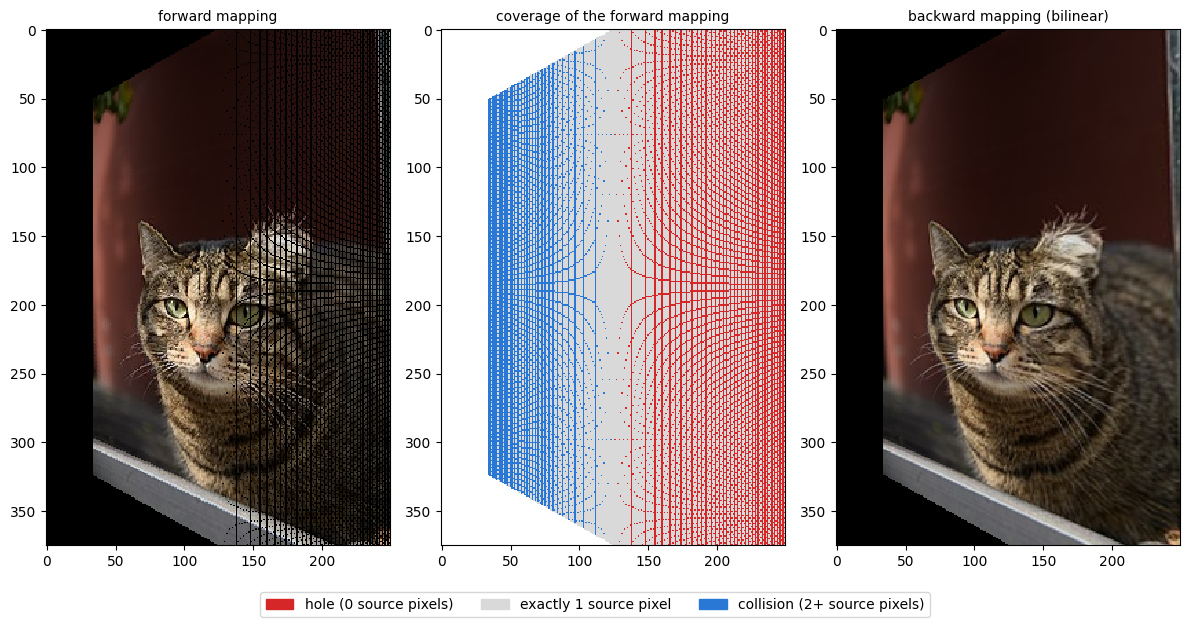

In [ ]:
H_mixed = translation(cx, cy) @ last_row_matrix(-0.003, 0) @ translation(-cx, -cy)
print('H = T(c) P T(-c) =\n', H_mixed)
fw, hits = forward_warp(img, H_mixed)
region = target_region(H_mixed, (width, height), (width, height))
for name, half in [('left half ', slice(0, width // 2)), ('right half', slice(width // 2, width))]:
    r, hh = region[:, half], hits[:, half]
    print(f'{name}: holes {np.sum(r & (hh == 0)) / r.sum():5.1%}, collisions {np.sum(hh > 1) / r.sum():5.1%} of the output region')

fig, axes = plt.subplots(1, 3, figsize=(12, 6.3))
axes[0].imshow(to_rgb(fw), interpolation='nearest')
axes[0].set_title('forward mapping', fontsize=10)
axes[1].imshow(coverage_image(hits, region), cmap=COVERAGE_CMAP, vmin=0, vmax=3, interpolation='nearest')
axes[1].set_title('coverage of the forward mapping', fontsize=10)
axes[2].imshow(to_rgb(backward_warp(img, H_mixed)), interpolation='nearest')
axes[2].set_title('backward mapping (bilinear)', fontsize=10)
fig.legend(handles=COVERAGE_LEGEND, loc='lower center', ncol=3)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

## 4. Points at Infinity, Vanishing Points and the Horizon
Why do parallel lines start to converge? A direction $(d_x, d_y)$ is the homogeneous vector $(d_x, d_y, 0)$,
the **point at infinity** where all lines with this direction meet.

- **Affine**: $\begin{bmatrix} A & \mathbf{t} \\ \mathbf{0}^\top & 1 \end{bmatrix}
  \begin{bmatrix} \mathbf{d} \\ 0 \end{bmatrix} = \begin{bmatrix} A\mathbf{d} \\ 0 \end{bmatrix}$: the
  third coordinate stays $0$, points at infinity stay at infinity, so **parallel lines stay parallel**.
- **Projective**: $H (1, 0, 0)^\top = (h_{11}, h_{21}, h_{31})^\top$. If $h_{31} \neq 0$, this is an
  ordinary, *finite* point $(h_{11}/h_{31},\; h_{21}/h_{31})$: the **vanishing point** where the images of all
  horizontal lines meet. The same holds for the vertical direction $(0, 1, 0)$ with $h_{32}$.

The points at infinity of all directions form the **line at infinity**, $\mathbf{l}_\infty = (0, 0, 1)^\top$
(a line $ax + by + c = 0$ is the homogeneous vector $(a, b, c)$, as in the line fitting classes). Lines
transform with the inverse transpose, $\mathbf{l}' = H^{-\top}\mathbf{l}$, so the image of the line at
infinity is the **horizon** (vanishing line) $H^{-\top}\mathbf{l}_\infty$, and all vanishing points lie on it.
$H^{-\top}\mathbf{l}_\infty$ is simply the last row of $H^{-1}$. For an affine map this is $(0, 0, 1)$ again,
so the line at infinity stays at infinity. A homography moves it into the image plane.

vanishing point of the horizontal lines: [333.3333   0.    ]
vanishing point of the vertical lines:   [  0. 500.]
horizon (a, b, c): [-0.003 -0.002  1.   ]  -> passes through both: True


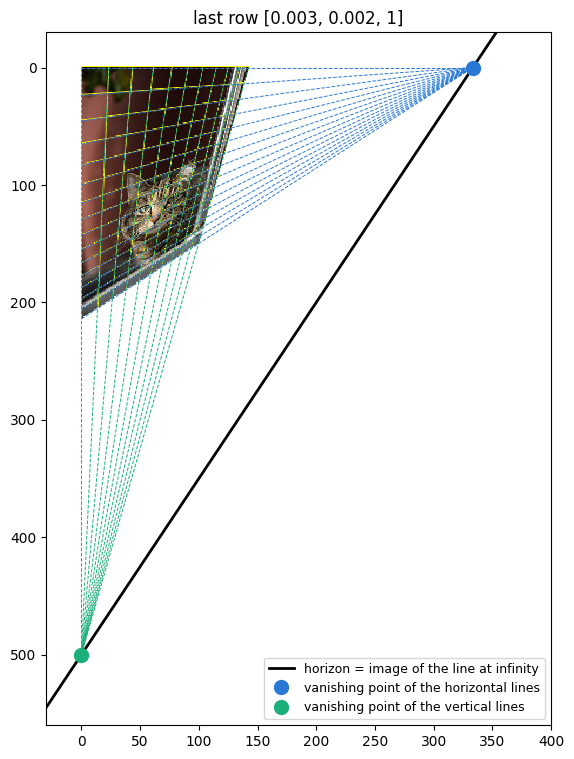

In [ ]:
def transform_points(H, pts):
    """Apply a 3x3 transformation to an (N, 2) array of points, including the division by the 3rd coordinate."""
    p = H @ np.vstack([np.asarray(pts, dtype=float).T, np.ones(len(pts))])
    return (p[:2] / p[2]).T


H_vp = last_row_matrix(0.003, 0.002)
vp_x = H_vp @ [1, 0, 0]                        # image of the point at infinity of the horizontal lines
vp_y = H_vp @ [0, 1, 0]                        # ... and of the vertical lines
horizon = np.linalg.inv(H_vp).T @ [0, 0, 1]    # image of the line at infinity
vp_x, vp_y = vp_x[:2] / vp_x[2], vp_y[:2] / vp_y[2]
print('vanishing point of the horizontal lines:', vp_x)
print('vanishing point of the vertical lines:  ', vp_y)
print('horizon (a, b, c):', horizon, ' -> passes through both:', np.allclose([horizon @ [*vp_x, 1], horizon @ [*vp_y, 1]], 0))

# the warped image, transparent outside the transformed image
warped = to_rgb(backward_warp(img_grid, H_vp))
alpha = target_region(H_vp, (width, height), (width, height), margin=0)
rgba = np.dstack([warped, 255 * alpha.astype(np.uint8)])

fig, ax = plt.subplots(figsize=(7, 9))
ax.imshow(rgba, interpolation='nearest')
grid_xs = list(range(0, width, 25)) + [width - 1]
grid_ys = list(range(0, height, 25)) + [height - 1]
for y in grid_ys:                              # extend the images of the horizontal grid lines ...
    p = transform_points(H_vp, [[0, y]])[0]
    ax.plot([p[0], vp_x[0]], [p[1], vp_x[1]], color='#2a78d6', lw=0.7, ls='--')
for x in grid_xs:                              # ... and of the vertical grid lines
    p = transform_points(H_vp, [[x, 0]])[0]
    ax.plot([p[0], vp_y[0]], [p[1], vp_y[1]], color='#1baf7a', lw=0.7, ls='--')
xx = np.array([-50, 450])
ax.plot(xx, -(horizon[0] * xx + horizon[2]) / horizon[1], 'k-', lw=2, label='horizon = image of the line at infinity')
ax.plot(*vp_x, 'o', color='#2a78d6', ms=10, label='vanishing point of the horizontal lines')
ax.plot(*vp_y, 'o', color='#1baf7a', ms=10, label='vanishing point of the vertical lines')
ax.set_xlim(-30, 400)
ax.set_ylim(560, -30)
ax.set_aspect('equal')
ax.legend(loc='lower right', fontsize=9)
ax.set_title(f'last row [{H_vp[2, 0]}, {H_vp[2, 1]}, {H_vp[2, 2]:.0f}]')
plt.show()

### 4.1 What else is lost?
Straight lines are preserved, but ratios of lengths along a line are not: the image of a midpoint is no
longer the midpoint of the images.

In [ ]:
P, Q = np.array([20.0, 30.0]), np.array([230.0, 340.0])
mid = (P + Q) / 2
for name, T in [('affine T_aff', T_aff), ('projective H_vp', H_vp)]:
    p, q, m = transform_points(T, [P, Q, mid])
    print(f'{name:>16}: image of the midpoint = {m},  midpoint of the images = {(p + q) / 2}')

    affine T_aff: image of the midpoint = [124.6499 185.5647],  midpoint of the images = [124.6499 185.5647]
 projective H_vp: image of the midpoint = [ 71.6332 106.0172],  midpoint of the images = [57.4518 85.1228]


## 5. Where Does Such a Matrix Come From? A Camera Looking at a Plane
A **pinhole camera** projects a 3D point $(X_c, Y_c, Z_c)$, given in camera coordinates, to the pixel
$$
x' = f\,\frac{X_c}{Z_c} + c_x, \qquad y' = f\,\frac{Y_c}{Z_c} + c_y
\qquad\Longleftrightarrow\qquad
\begin{bmatrix} u \\ v \\ w \end{bmatrix} = K \begin{bmatrix} X_c \\ Y_c \\ Z_c \end{bmatrix},\quad
K = \begin{bmatrix} f & 0 & c_x \\ 0 & f & c_y \\ 0 & 0 & 1 \end{bmatrix}.
$$
Here the third homogeneous coordinate is $w = Z_c$, the **depth**, and the perspective division is the
division by depth: objects twice as far appear half as large.

Now print the cat on a flat poster. A point of the poster has coordinates $(X, Y, 0)$ in the poster's own
frame. The camera sees it at $\mathbf{X}_c = R\,(X, Y, 0)^\top + \mathbf{t}$, where $R$ is the rotation of the
poster and $\mathbf{t}$ its position. Because the third coordinate is $0$, the third column of $R$ drops out:
$$
\begin{bmatrix} u \\ v \\ w \end{bmatrix} =
K \begin{bmatrix} \mathbf{r}_1 & \mathbf{r}_2 & \mathbf{t} \end{bmatrix}
\begin{bmatrix} X \\ Y \\ 1 \end{bmatrix} = H \begin{bmatrix} X \\ Y \\ 1 \end{bmatrix}.
$$
**The image of a plane is a homography of it.** The last row of $K[\mathbf{r}_1\; \mathbf{r}_2\; \mathbf{t}]$
is $[r_{31} \;\; r_{32} \;\; t_z]$, so $w = r_{31}X + r_{32}Y + t_z$ is the depth of the poster point:

- poster **parallel** to the image plane ($r_{31} = r_{32} = 0$): the same depth everywhere, the last row is
  $[0 \;\; 0 \;\; t_z]$, so the map is **affine** (in fact, a similarity);
- poster **tilted**: the depth changes across the poster, so $h_{31}, h_{32} \neq 0$ and we get **perspective**.

So changing the last row means making the **depth** vary across the image. Below, the poster is centered in
front of the camera at distance $d = 650$ px, a bit farther than the focal length $f = 500$ px, so that the
whole tilted poster stays in the frame. It is rotated about its vertical or horizontal axis. We scale $H$ so
that $w = 1$ at the image center; then $w = Z_c / d$ at every point.

tilt about x: 0°, about y: 0°    last row = [+0.00000, +0.00000, 1.000],  w = depth/d at the 4 corners: [1. 1. 1. 1.]
tilt about x: 0°, about y: 40°   last row = [-0.00099, +0.00000, 1.123],  w = depth/d at the 4 corners: [1.123 0.877 0.877 1.123]
tilt about x: 0°, about y: -40°  last row = [+0.00099, +0.00000, 0.877],  w = depth/d at the 4 corners: [0.877 1.123 1.123 0.877]
tilt about x: 40°, about y: 0°   last row = [+0.00000, +0.00099, 0.815],  w = depth/d at the 4 corners: [0.815 0.815 1.185 1.185]
tilt about x: -40°, about y: 0°  last row = [+0.00000, -0.00099, 1.185],  w = depth/d at the 4 corners: [1.185 1.185 0.815 0.815]


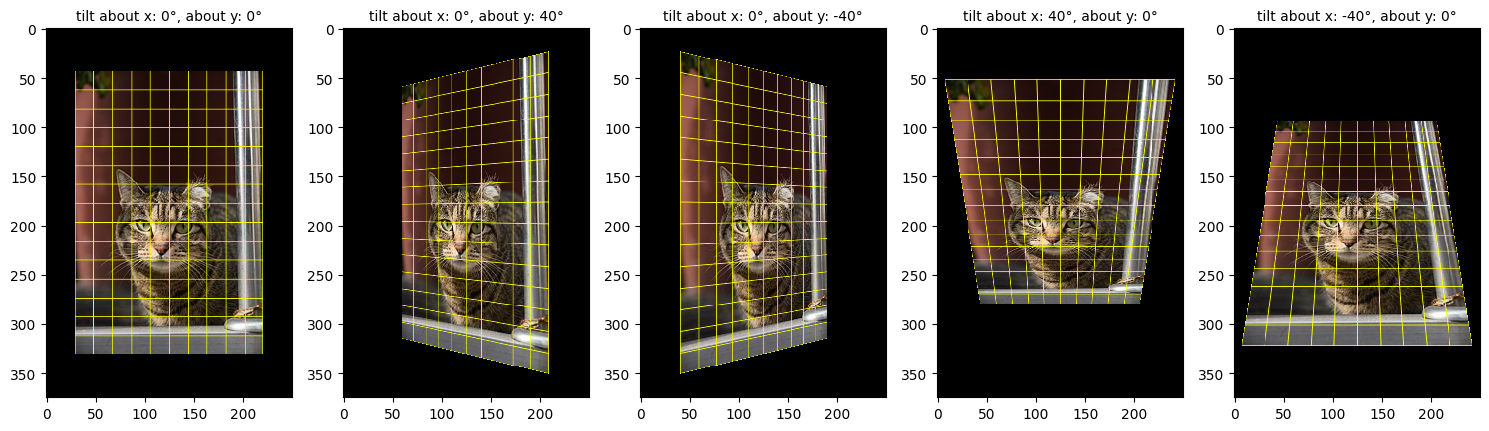

In [ ]:
def poster_homography(tilt_x_deg=0.0, tilt_y_deg=0.0, f=500.0, d=650.0, size=(width, height)):
    """Homography of a pinhole camera (focal length f, principal point = image center) looking at the image
    printed on a poster at distance d, rotated about the poster's horizontal (x) and vertical (y) axes."""
    w, h = size
    cx, cy = (w - 1) / 2, (h - 1) / 2
    ax, ay = np.deg2rad(tilt_x_deg), np.deg2rad(tilt_y_deg)
    Rx = np.array([[1, 0, 0], [0, np.cos(ax), -np.sin(ax)], [0, np.sin(ax), np.cos(ax)]])
    Ry = np.array([[np.cos(ay), 0, np.sin(ay)], [0, 1, 0], [-np.sin(ay), 0, np.cos(ay)]])
    R = Ry @ Rx
    t = np.array([0, 0, d])
    K = np.array([[f, 0, cx], [0, f, cy], [0, 0, 1]])
    # poster coordinates (X, Y) = pixel coordinates measured from the image center
    H = K @ np.column_stack([R[:, 0], R[:, 1], t]) @ translation(-cx, -cy)
    return H / d                                  # w = Z_c / d, i.e. w = 1 at the image center


tilts = [(0, 0), (0, 40), (0, -40), (40, 0), (-40, 0)]
images, titles = [], []
for tx_deg, ty_deg in tilts:
    H_cam = poster_homography(tx_deg, ty_deg)
    images.append(backward_warp(img_grid, H_cam))
    titles.append(f'tilt about x: {tx_deg}°, about y: {ty_deg}°')
    corners = np.array([[0, 0, 1], [width - 1, 0, 1], [width - 1, height - 1, 1], [0, height - 1, 1]]).T
    h31, h32, h33 = H_cam[2]
    print(f'{titles[-1]:<32} last row = [{h31:+.5f}, {h32:+.5f}, {h33:.3f}],'
          f'  w = depth/d at the 4 corners: {np.round(H_cam[2] @ corners, 3)}')
show_images(images, titles, cols=5, size=3)

Without tilt, the last row is $[0 \;\; 0 \;\; 1]$ and we get a uniformly scaled copy ($f/d$): a similarity.
With tilt, the far side of the poster ($w > 1$) shrinks and the near side ($w < 1$) grows. A rotation about
the vertical axis ($y$ tilt) produces a non-zero $h_{31}$, a rotation about the horizontal axis ($x$ tilt) a
non-zero $h_{32}$. The magnitudes are just like in our experiments in Section 3.2: for a $y$ tilt by $\theta$,
$h_{31} = -\sin\theta / d$, so $40^\circ$ at $d = 650$ px gives $|h_{31}| \approx 0.001$.

## 6. Homographies in OpenCV: `cv2.warpPerspective` and `cv2.getPerspectiveTransform`
- `cv2.warpPerspective(src, H, dsize, flags, borderMode, borderValue)` works like `warpAffine`, but takes the
  full $3 \times 3$ matrix and performs the perspective division. It uses backward mapping as well.
- A homography has 8 degrees of freedom, so it is determined by **4 point correspondences** (no 3 of them
  collinear). `cv2.getPerspectiveTransform(src, dst)` computes it from exactly 4 pairs (`float32`, shape
  $4 \times 2$). This is what an affine map could not do: map a rectangle to **any** quadrilateral.
- With more (noisy) correspondences and outliers: `cv2.findHomography(src, dst, cv2.RANSAC)`. We implement
  the estimation ourselves in Sections 9 to 12 (the DLT algorithm, then RANSAC).

A classic application is **rectification**: take a photo of a planar object (a document, a facade, a
poster) seen at an angle, mark its 4 corners, and map them to a rectangle. Below we tilt the poster by
$60^\circ$, find where its corners ended up (in practice they are clicked or detected), and map them back.

our backward_warp vs. cv2.warpPerspective, pixels that differ by more than 3: 0.47%
H_rect @ H_tilt (normalized) =
 [[ 1.  0. -0.]
 [ 0.  1. -0.]
 [ 0.  0.  1.]]


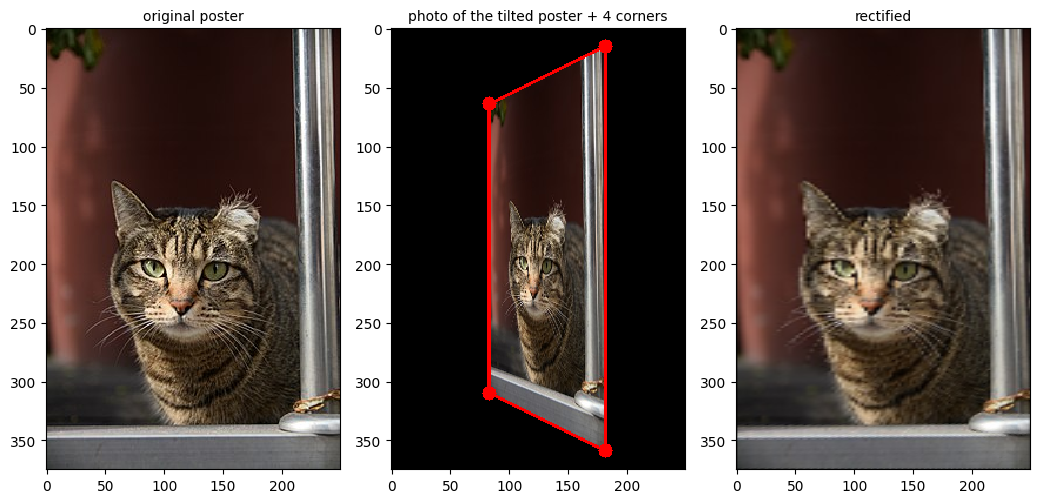

In [ ]:
H_tilt = poster_homography(0, 60)
tilted = cv2.warpPerspective(img, H_tilt, (width, height), flags=cv2.INTER_LINEAR)
print('our backward_warp vs. cv2.warpPerspective, pixels that differ by more than 3:',
      f'{np.mean(np.abs(backward_warp(img, H_tilt).astype(int) - tilted.astype(int)) > 3):.2%}')

corners = np.float32([[0, 0], [width - 1, 0], [width - 1, height - 1], [0, height - 1]])
corners_tilted = cv2.perspectiveTransform(corners[None], H_tilt)[0]      # where the 4 corners are in the photo
H_rect = cv2.getPerspectiveTransform(corners_tilted, corners)            # 4 point pairs -> homography
rectified = cv2.warpPerspective(tilted, H_rect, (width, height), flags=cv2.INTER_LINEAR)

H_check = H_rect @ H_tilt
print('H_rect @ H_tilt (normalized) =\n', H_check / H_check[2, 2])

tilted_vis = tilted.copy()
cv2.polylines(tilted_vis, [np.round(corners_tilted).astype(np.int32)], True, (0, 0, 255), 2)
for p in corners_tilted:
    cv2.circle(tilted_vis, (int(round(p[0])), int(round(p[1]))), 6, (0, 0, 255), -1)
show_images([img, tilted_vis, rectified], ['original poster', 'photo of the tilted poster + 4 corners', 'rectified'])

$H_{rect} H_{tilt}$ is the identity (up to scale), so the geometry is fully recovered. The image itself is
not: the far (left) side of the poster was compressed in the photo, and those pixels are gone. The
rectified image is blurry there. This is the resolution difference we met with forward mapping in the previous class.

## 7. Try It Yourself (Interactive)
If `ipywidgets` is available (it is in Colab), the sliders below change the last row of $H$.

In [ ]:
try:
    from ipywidgets import interact, FloatSlider
except ImportError:
    interact = None
    print('ipywidgets is not installed (pip install ipywidgets), skipping the interactive demo.')

if interact is not None:
    def explore_last_row(h31=0.0, h32=0.0, h33=1.0):
        H = last_row_matrix(h31, h32, h33)
        out = cv2.warpPerspective(img_grid, H, (width, height))
        show_images([img_grid, out], ['original', f'last row [{h31:.4f}, {h32:.4f}, {h33:.2f}]'], size=4)

    interact(explore_last_row,
             h31=FloatSlider(min=-0.003, max=0.003, step=0.0001, value=0.0, readout_format='.4f'),
             h32=FloatSlider(min=-0.002, max=0.002, step=0.0001, value=0.0, readout_format='.4f'),
             h33=FloatSlider(min=0.25, max=2.0, step=0.05, value=1.0))

interactive(children=(FloatSlider(value=0.0, description='h31', max=0.003, min=-0.003, readout_format='.4f', s…

---
## 8. When Are Two Photos Related by a Homography?
So far we created the second image ourselves, by warping the first one with a known $H$. From now on we take two
**photos** of the same scene and look for the homography between them. A pixel $\mathbf{x}_1$ of the first photo and
a pixel $\mathbf{x}_2$ of the second one that show the same 3D point form a **correspondence**
$\mathbf{x}_1 \leftrightarrow \mathbf{x}_2$. In general, no single $H$ maps every $\mathbf{x}_1$ to its $\mathbf{x}_2$:
where a point appears in the second photo depends on its depth. There are two exceptions. Below, $\simeq$ means
equality up to a non-zero scale factor, as always for homogeneous vectors.

**(a) The scene is a plane.** By Section 5, each camera maps the plane to its image with a homography:
$\mathbf{x}_1 \simeq H_1\mathbf{X}$ and $\mathbf{x}_2 \simeq H_2\mathbf{X}$, where $\mathbf{X} = (X, Y, 1)$ is a point of the plane.
Hence $\mathbf{x}_2 \simeq H_2 H_1^{-1}\mathbf{x}_1$. This is what we used for rectification in Section 6.

**(b) The camera only rotates about its projection center.** We work in the camera coordinate system of the first
photo. A point $\mathbf{X}_c$ appears at $\mathbf{x}_1 \simeq K\mathbf{X}_c$, so it lies on the ray
$\mathbf{X}_c = Z_c K^{-1}\mathbf{x}_1$, where $Z_c$ is its (unknown) depth. The second photo is taken by the same
camera, rotated by $R$, so it sees the point at $\mathbf{x}_2 \simeq KR\mathbf{X}_c$:
$$
\mathbf{x}_2 \simeq KR\,(Z_c K^{-1}\mathbf{x}_1) \simeq \underbrace{KRK^{-1}}_{H}\,\mathbf{x}_1 .
$$
The depth drops out. The ray of $\mathbf{x}_1$ starts at the projection center, which is the same for both photos,
so the second camera also sees the whole ray as a single point. This holds for **any** scene, flat or not, and it is
the basis of panoramas: we turn the camera, but we do not move it.

**What if the camera also moves?** If the projection center moves by $\mathbf{c}$, the second camera sees
$KR(\mathbf{X}_c - \mathbf{c}) = Z_c\left(KRK^{-1}\mathbf{x}_1 - \frac{1}{Z_c}KR\,\mathbf{c}\right)$, so
$$
\mathbf{x}_2 \simeq KRK^{-1}\mathbf{x}_1 - \frac{1}{Z_c}\,KR\,\mathbf{c}.
$$
The second term depends on the depth: this is **parallax**. It is about $f\,|\mathbf{c}| / Z_c$ pixels, so it is negligible
for distant objects and large for close ones. (Points at infinity, $Z_c \to \infty$, still follow $KRK^{-1}$, which is
why it is called the *infinite homography*.)

### 8.1 Our data: two photos of a landscape
The two photos below are from the course website. The camera was turned to the right between the two shots. The
landscape is far away, so a small movement of a hand-held camera causes no visible parallax, and one homography
should map one photo onto the other. 8 correspondences were clicked by hand; in `features.txt` the first two rows are
their $x$ and $y$ coordinates in `a.png`, the last two rows those in `b.png`.

b.png and a.png: width = 500, height = 375;  8 correspondences


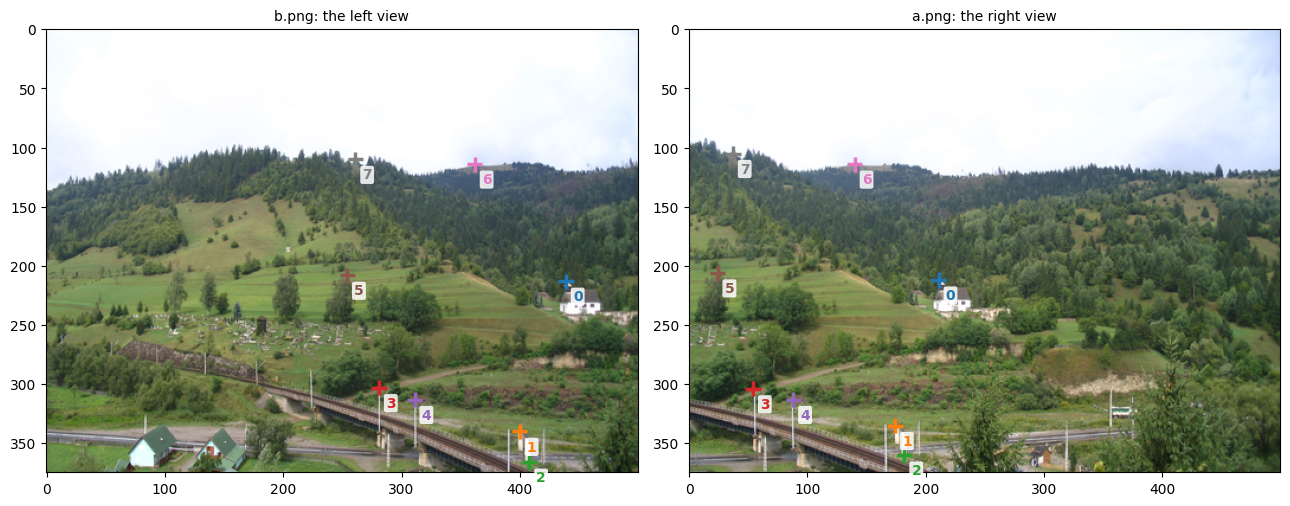

In [ ]:
PANO_URL = 'https://cv.inf.elte.hu/wp-content/uploads/2025/03/lab6-3dcv.zip'
DATA_DIR = 'data'
PANO_FILES = ['a.png', 'b.png', 'features.txt']

if not all(os.path.exists(os.path.join(DATA_DIR, name)) for name in PANO_FILES):
    zip_path, _ = urllib.request.urlretrieve(PANO_URL)          # download into a temporary file
    with zipfile.ZipFile(zip_path) as archive:
        for name in PANO_FILES:                                 # skip the macOS metadata (__MACOSX/) in the archive
            archive.extract(name, DATA_DIR)
    urllib.request.urlcleanup()                                 # delete the temporary file

img_left = cv2.imread(os.path.join(DATA_DIR, 'b.png'))          # the left view
img_right = cv2.imread(os.path.join(DATA_DIR, 'a.png'))         # the right view
features = np.loadtxt(os.path.join(DATA_DIR, 'features.txt'))   # 4 x 8: x and y in a.png, then x and y in b.png
pts_right, pts_left = features[:2].T, features[2:].T            # (8, 2) arrays; row i of both is a correspondence
print(f'b.png and a.png: width = {img_left.shape[1]}, height = {img_left.shape[0]};  {len(pts_left)} correspondences')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = plt.cm.tab10(np.arange(len(pts_left)))
for ax, im, pts, title in [(axes[0], img_left, pts_left, 'b.png: the left view'),
                           (axes[1], img_right, pts_right, 'a.png: the right view')]:
    ax.imshow(to_rgb(im))
    ax.scatter(pts[:, 0], pts[:, 1], s=120, c=colors, marker='+', linewidths=2.5)
    for i, (x, y) in enumerate(pts):
        ax.annotate(str(i), (x, y), xytext=(5, -14), textcoords='offset points', fontsize=10, fontweight='bold',
                    color=colors[i], bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.85))
    ax.set_title(title, fontsize=10)
plt.tight_layout()
plt.show()

Point 0 (the white house) is at $x = 211$ in `a.png` and at $x = 439$ in `b.png`: the content moved about 230 pixels to
the left, so `a.png` shows the part of the scene to the right of `b.png`. We take `b.png` as the **reference** photo and
look for the homography that maps the right photo into it: $\mathbf{x}_{\mathrm{left}} \simeq H\,\mathbf{x}_{\mathrm{right}}$.

---

## 9. Estimating a Homography: the DLT Algorithm
Given $N$ correspondences $\mathbf{x}_i \leftrightarrow \mathbf{x}'_i$, with $\mathbf{x}_i = (x_i, y_i, 1)$ and
$\mathbf{x}'_i = (x'_i, y'_i, 1)$, we look for $H$ with $\mathbf{x}'_i \simeq H\mathbf{x}_i$. Let
$\mathbf{h}_1^\top, \mathbf{h}_2^\top, \mathbf{h}_3^\top$ be the rows of $H$. The perspective division (Section 3) gives
$$
x' = \frac{\mathbf{h}_1^\top\mathbf{x}}{\mathbf{h}_3^\top\mathbf{x}}, \qquad
y' = \frac{\mathbf{h}_2^\top\mathbf{x}}{\mathbf{h}_3^\top\mathbf{x}}.
$$
Multiplying by the denominator gives two equations that are **linear** in the entries of $H$:
$$
\mathbf{h}_1^\top\mathbf{x} - x'\,\mathbf{h}_3^\top\mathbf{x} = 0, \qquad
\mathbf{h}_2^\top\mathbf{x} - y'\,\mathbf{h}_3^\top\mathbf{x} = 0.
$$
With $\mathbf{h} = (h_{11}, h_{12}, h_{13}, h_{21}, \dots, h_{33})^\top$ (the rows of $H$ one after the other), every
correspondence contributes two rows to a homogeneous linear system $A\mathbf{h} = \mathbf{0}$:
$$
\begin{bmatrix}
x & y & 1 & 0 & 0 & 0 & -x'x & -x'y & -x' \\
0 & 0 & 0 & x & y & 1 & -y'x & -y'y & -y'
\end{bmatrix} \mathbf{h} = \mathbf{0}.
$$
This is the **Direct Linear Transformation (DLT)**. With $N$ correspondences, $A$ is a $2N \times 9$ matrix.

- $\mathbf{h}$ is only defined up to scale (Section 3.1), so we look for a **unit** vector: minimize $\|A\mathbf{h}\|^2$
  subject to $\|\mathbf{h}\| = 1$. As for the homogeneous line fit in the previous classes, the solution is the
  eigenvector of $A^\top A$ with the smallest eigenvalue, that is, the right singular vector of $A$ with the smallest
  singular value: the last row of $V^\top$ in the SVD $A = U\Sigma V^\top$. At the end we divide by $h_{33}$ (OpenCV's
  convention).
- **4 correspondences** (no 3 of them collinear) give 8 independent equations: $A$ has rank 8, its null space is
  one-dimensional and $H$ is exact. This is what `cv2.getPerspectiveTransform` computes.
- With **more** correspondences and noise, $A$ has full rank and $A\mathbf{h} = \mathbf{0}$ has no exact solution. The DLT
  then minimizes $\|A\mathbf{h}\|$, the **algebraic error**, which has no direct geometric meaning. The error we really
  care about is the **transfer error** $\|\mathbf{x}'_i - H(\mathbf{x}_i)\|$ in pixels, where $H(\mathbf{x}_i)$ includes the
  perspective division.

With 4 correspondences, $A$ is $8 \times 9$, and a reduced SVD would return only 8 rows of $V^\top$, without the null
vector we need. `np.linalg.svd` returns the full $V^\top$ by default; `cv2.SVDecomp` needs the flag `cv2.SVD_FULL_UV`.

In [ ]:
def dlt_matrix(src, dst):
    """The 2N x 9 DLT matrix A: two rows for every correspondence src[i] -> dst[i] ((N, 2) arrays of (x, y))."""
    x, y = src[:, 0], src[:, 1]
    xp, yp = dst[:, 0], dst[:, 1]                          # x' and y'
    zero, one = np.zeros_like(x), np.ones_like(x)
    rows_x = np.column_stack([x, y, one, zero, zero, zero, -xp * x, -xp * y, -xp])
    rows_y = np.column_stack([zero, zero, zero, x, y, one, -yp * x, -yp * y, -yp])
    return np.stack([rows_x, rows_y], axis=1).reshape(-1, 9)   # rows 2i and 2i + 1 belong to correspondence i


def fit_homography_dlt(src, dst, solver='numpy'):
    """Homography H with dst ~ H src from N >= 4 correspondences (DLT, without normalization).

    src, dst: (N, 2) arrays of corresponding points (x, y).
    solver: 'numpy' -> np.linalg.svd, 'opencv' -> cv2.SVDecomp.
    Returns H scaled so that H[2, 2] = 1.
    """
    A = dlt_matrix(np.asarray(src, dtype=float), np.asarray(dst, dtype=float))
    if solver == 'numpy':
        _, _, Vt = np.linalg.svd(A, full_matrices=True)        # Vt is 9 x 9, even if A is 8 x 9
    elif solver == 'opencv':
        _, _, Vt = cv2.SVDecomp(A, flags=cv2.SVD_FULL_UV)
    else:
        raise ValueError(solver)
    H = Vt[-1].reshape(3, 3)                                   # the right singular vector of the smallest singular value
    return H / H[2, 2]


# the minimal case: the 4 corners of the tilted poster from Section 6
A4 = dlt_matrix(corners_tilted.astype(float), corners.astype(float))
print(f'4 correspondences: A is {A4.shape[0]} x {A4.shape[1]}, rank {np.linalg.matrix_rank(A4)}')
for solver in ['numpy', 'opencv']:
    print(f'{solver:>6}: DLT == cv2.getPerspectiveTransform (H_rect):',
          np.allclose(fit_homography_dlt(corners_tilted, corners, solver), H_rect / H_rect[2, 2]))

4 correspondences: A is 8 x 9, rank 8
 numpy: DLT == cv2.getPerspectiveTransform (H_rect): True
opencv: DLT == cv2.getPerspectiveTransform (H_rect): True


Now the 8 hand-clicked correspondences of the panorama, mapped from the right photo to the left one:

In [ ]:
def transfer_error(H, src, dst):
    """Distance in pixels between the mapped points H(src) and their correspondences dst."""
    return np.linalg.norm(transform_points(H, src) - dst, axis=1)


H_np = fit_homography_dlt(pts_right, pts_left, 'numpy')
H_cv = fit_homography_dlt(pts_right, pts_left, 'opencv')
print('H (DLT, 8 correspondences) =\n', H_np)
print('np.linalg.svd and cv2.SVDecomp agree:', np.allclose(H_np, H_cv))

err = transfer_error(H_np, pts_right, pts_left)
print('transfer errors [px]:', err.round(2), f'  RMS = {np.sqrt(np.mean(err**2)):.3f} px')

H (DLT, 8 correspondences) =
 [[  0.7558   0.0308 227.2881]
 [ -0.1207   0.9644  12.2228]
 [ -0.0005   0.0001   1.    ]]
np.linalg.svd and cv2.SVDecomp agree: True
transfer errors [px]: [0.44 0.58 0.33 0.57 1.82 1.96 0.79 1.33]   RMS = 1.148 px


The transfer errors are 0.3 to 2 pixels: the points were clicked by hand, at integer coordinates, so 8 points do not fit
any homography exactly. Note the last row of $H$: $h_{31} < 0$, so $w < 1$ on the right side of `a.png`, which gets
enlarged when mapped into the frame of `b.png` (Section 3.2). We will see this in the panorama.

---

## 10. Data Normalization
Look at the columns of $A$: $1$, then $x$ and $y$ (hundreds of pixels), then products like $x'x$ (around $10^5$).
The entries differ by 5 orders of magnitude, and so do the singular values of $A$. Two consequences:

- **Numerical:** the eigenvalues of $A^\top A$ are the squares of the singular values of $A$, so they span about
  15 orders of magnitude: the whole precision of a double (about 16 digits). Computing the DLT from the
  eigenvectors of $A^\top A$ instead of the SVD of $A$ is risky.
- **Statistical:** the algebraic error $\|A\mathbf{h}\|$ weights the equations very unequally, and it depends on the
  coordinate system. Moving the origin of the pixel coordinates is a perfectly valid choice, yet it changes the
  result of the DLT.

The remedy (Hartley, 1997) is to **normalize** the points of each image with a similarity transformation $T$ first:
move their **centroid** to the origin, and scale them so that their **mean distance from the origin is $\sqrt{2}$**
(a "typical" point becomes $(\pm 1, \pm 1)$):
$$
T = \begin{bmatrix} s & 0 & -s\bar{x} \\ 0 & s & -s\bar{y} \\ 0 & 0 & 1 \end{bmatrix}, \qquad
(\bar{x}, \bar{y}) = \frac{1}{N}\sum_{i=1}^N (x_i, y_i), \qquad
s = \frac{\sqrt{2}}{\frac{1}{N}\sum_{i=1}^N \sqrt{(x_i - \bar{x})^2 + (y_i - \bar{y})^2}}.
$$
**Denormalization.** Each image gets its own normalization: $\tilde{\mathbf{x}} = T\mathbf{x}$ and
$\tilde{\mathbf{x}}' = T'\mathbf{x}'$. The DLT on the normalized points gives $\tilde{H}$ with
$\tilde{\mathbf{x}}' \simeq \tilde{H}\tilde{\mathbf{x}}$, that is, $T'\mathbf{x}' \simeq \tilde{H}T\mathbf{x}$. $T'$ is invertible, so
$$
\mathbf{x}' \simeq T'^{-1}\tilde{H}T\,\mathbf{x}, \qquad\text{hence}\qquad H = T'^{-1}\tilde{H}\,T.
$$
The normalized DLT gives the same $H$ whatever the origin and the unit of the pixel coordinates (Hartley and Zisserman,
*Multiple View Geometry*, Section 4.4). `cv2.findHomography` normalizes the points internally as well.

In [ ]:
def normalization_matrix(pts):
    """Similarity T that moves the centroid of the (N, 2) points to the origin and scales their mean distance to sqrt(2)."""
    centroid = pts.mean(axis=0)
    s = np.sqrt(2) / np.mean(np.linalg.norm(pts - centroid, axis=1))
    return np.array([[s, 0, -s * centroid[0]],
                     [0, s, -s * centroid[1]],
                     [0, 0, 1]])


def fit_homography(src, dst, solver='numpy'):
    """Normalized DLT: homography H with dst ~ H src from N >= 4 correspondences. Returns H with H[2, 2] = 1."""
    src, dst = np.asarray(src, dtype=float), np.asarray(dst, dtype=float)
    T_src, T_dst = normalization_matrix(src), normalization_matrix(dst)
    H_norm = fit_homography_dlt(transform_points(T_src, src), transform_points(T_dst, dst), solver)
    H = np.linalg.inv(T_dst) @ H_norm @ T_src                  # denormalization
    return H / H[2, 2]


T_right, T_left = normalization_matrix(pts_right), normalization_matrix(pts_left)
n_right, n_left = transform_points(T_right, pts_right), transform_points(T_left, pts_left)
print(f'normalized points of a.png: centroid {n_right.mean(axis=0).round(12) + 0},'
      f' mean distance from the origin {np.mean(np.linalg.norm(n_right, axis=1)):.4f}')
for name, A in [('pixel coordinates', dlt_matrix(pts_right, pts_left)), ('normalized', dlt_matrix(n_right, n_left))]:
    print(f'\n{name}:\n  column norms of A:      {np.linalg.norm(A, axis=0).round(1)}'
          f'\n  singular values of A:   {np.linalg.svd(A, compute_uv=False)}')

normalized points of a.png: centroid [0. 0.], mean distance from the origin 1.4142

pixel coordinates:
  column norms of A:      [   374.3    737.3      2.8    374.3    737.3      2.8 184108.4 350356.9
   1229.5]
  singular values of A:   [388784.2254  74126.6643    803.6924    354.2621    195.0743     60.9965
     32.5905      0.4588      0.014 ]

normalized:
  column norms of A:      [2.4 3.3 2.8 2.4 3.3 2.8 3.6 5.6 4.1]
  singular values of A:   [6.4583 5.1363 3.634  3.4255 2.5383 2.2509 1.8631 1.5838 0.0244]


After normalization all columns of $A$ have similar norms, and the singular values span 2 orders of magnitude instead
of 7. Does it matter for the result? We fit the 8 correspondences again, but measure the pixel coordinates from a
different origin: we add the same shift to all coordinates in both photos, fit $H_s$, and transform it back to the
original pixel coordinates, $H = S^{-1}H_sS$, where $S$ is the translation. The table shows the RMS transfer error in the
original coordinates for three methods: the DLT via the SVD (as in Section 9), the DLT via the eigenvectors of
$A^\top A$, and the normalized DLT.

In [ ]:
def fit_homography_eig(src, dst):
    """DLT via the eigenvector of A^T A with the smallest eigenvalue (without normalization)."""
    A = dlt_matrix(np.asarray(src, dtype=float), np.asarray(dst, dtype=float))
    eigenvalues, eigenvectors = np.linalg.eigh(A.T @ A)        # ascending eigenvalues, eigenvectors as columns
    H = eigenvectors[:, 0].reshape(3, 3)
    return H / H[2, 2]


methods = [('DLT (SVD)', fit_homography_dlt), ('DLT (eig. of A^T A)', fit_homography_eig), ('normalized DLT', fit_homography)]
print('RMS transfer error [px] of the 8 correspondences, with the origin of the pixel coordinates moved')
print(f'{"shift":>6} |' + ' |'.join(f'{name:>20}' for name, _ in methods))
for shift in [0, 100, 1000, 3000, 10000]:
    S = translation(shift, shift)                              # new coordinates = old coordinates + shift (in both photos)
    rms = []
    for _, fit in methods:
        H = np.linalg.inv(S) @ fit(transform_points(S, pts_right), transform_points(S, pts_left)) @ S
        rms.append(np.sqrt(np.mean(transfer_error(H, pts_right, pts_left)**2)))
    print(f'{shift:>6} |' + ' |'.join(f'{e:>20.4f}' for e in rms))

RMS transfer error [px] of the 8 correspondences, with the origin of the pixel coordinates moved
 shift |           DLT (SVD) | DLT (eig. of A^T A) |      normalized DLT
     0 |              1.1478 |              1.1478 |              1.1467
   100 |              1.1512 |              1.1512 |              1.1467
  1000 |              1.2192 |              1.2077 |              1.1467
  3000 |              1.2374 |             15.5276 |              1.1467
 10000 |              1.2389 |             36.8337 |              1.1467


The normalized DLT gives exactly the same answer for every origin. The plain DLT drifts as the origin moves away, and
via $A^\top A$ it breaks down once the coordinates are in the thousands (which is the normal range for today's
photos). With the original origin, all three give practically the same $H$ here: in double precision and for a small
image, the plain DLT happens to work, but nothing guarantees it. From now on we always use the normalized DLT,
`fit_homography`.

Finally, we compare it with OpenCV. With `method=0`, `cv2.findHomography` uses all points (no RANSAC): it starts from a
normalized DLT, then refines $H$ with the Levenberg-Marquardt algorithm, minimizing the sum of squared transfer errors
directly. Its RMS error is therefore slightly lower than ours.

In [ ]:
H_manual = fit_homography(pts_right, pts_left)
H_opencv, _ = cv2.findHomography(pts_right, pts_left, 0)       # method 0: least squares over all points
for name, H in [('normalized DLT (ours)', H_manual), ('cv2.findHomography', H_opencv)]:
    err = transfer_error(H, pts_right, pts_left)
    print(f'{name:>22}: RMS transfer error {np.sqrt(np.mean(err**2)):.4f} px, max {err.max():.4f} px')
print('H_manual =\n', H_manual)

 normalized DLT (ours): RMS transfer error 1.1467 px, max 2.0002 px
    cv2.findHomography: RMS transfer error 1.1461 px, max 2.0277 px
H_manual =
 [[  0.7577   0.0331 227.0685]
 [ -0.1205   0.9675  11.9089]
 [ -0.0005   0.0001   1.    ]]


---
## 11. Panorama Stitching
$H$ maps the right photo into the coordinate system of the reference (left) photo. To build the panorama:

1. **Canvas.** Map the 4 corners of the right photo with $H$. Together with the corners of the reference photo they
   give the bounding box of the panorama. Part of it may have negative coordinates (here the right photo reaches
   above the top of the left one), so we shift everything by a translation $T$ that moves the top-left corner of the
   bounding box to $(0, 0)$.
2. **Warping.** The reference photo is warped with $T$, the other one with $TH$ (first into the reference frame, then
   shifted). `cv2.warpPerspective` uses backward mapping (Section 6), so there are no holes. Its `flags` argument
   selects the interpolation, as in the previous class.
3. **Blending.** Where the photos overlap, we must decide which pixel values to keep:
   - **overwrite:** paste the reference photo over the other one. Simple, but the exposure of the two photos differs a
     little, so the border of the reference photo shows up as a **seam**;
   - **average:** the mean of the photos that cover a pixel. We warp every photo and its **mask** (an image of ones)
     with the same matrix, and divide the sum of the warped photos by the sum of the warped masks, which counts the
     photos at each pixel. Along the borders of a warped photo its warped mask is between 0 and 1, so the partially
     covered pixels get the right weight too. The weights still jump at the borders of the overlap, from $(1, 0)$ to
     $(\frac{1}{2}, \frac{1}{2})$, so the seams get weaker but stay sharp. A smooth transition (**feathering**) is
     Exercise 6 at the end.

canvas translation T =
 [[ 1.  0. -0.]
 [ 0.  1. 67.]
 [ 0.  0.  1.]] 
panorama size (width, height): (835, 486)


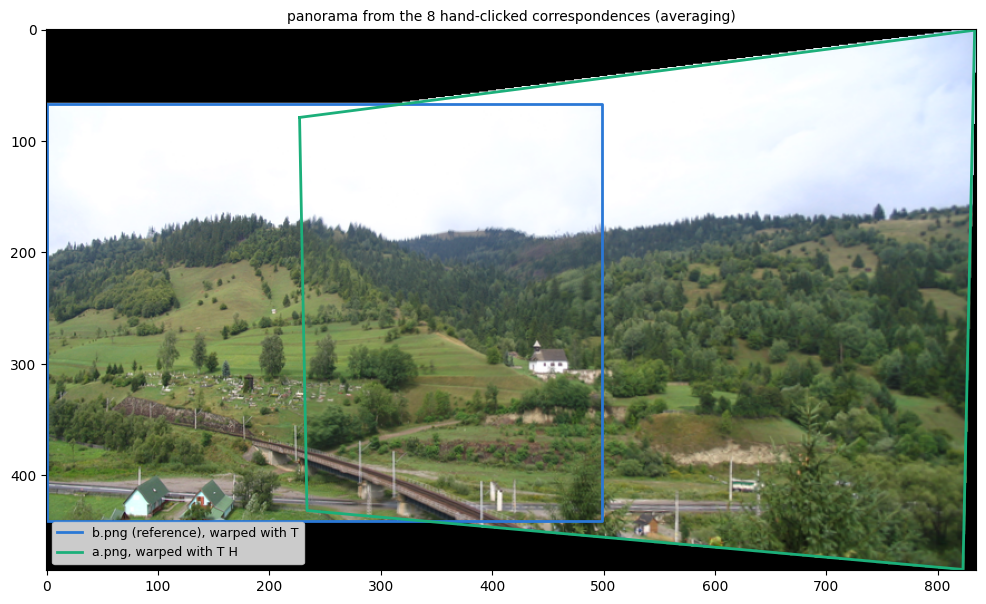

In [ ]:
def image_corners(w, h):
    """The 4 corner pixels of a w x h image, clockwise from the top-left one, as a (4, 2) array of (x, y)."""
    return np.array([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]], dtype=float)


def stitch(img_ref, img_src, H, blend='average', flags=cv2.INTER_LINEAR):
    """Panorama of two images: img_src is warped into the frame of img_ref with H (x_ref ~ H x_src).

    blend: 'overwrite' or 'average'; flags: the interpolation of cv2.warpPerspective.
    Returns the panorama and the translation T of the canvas.
    """
    h_r, w_r = img_ref.shape[:2]
    h_s, w_s = img_src.shape[:2]

    # 1. canvas: the bounding box of the reference image and of the warped corners of the other one
    corners_all = np.vstack([image_corners(w_r, h_r), transform_points(H, image_corners(w_s, h_s))])
    x_min, y_min = np.floor(corners_all.min(axis=0))
    x_max, y_max = np.ceil(corners_all.max(axis=0))
    T = translation(-x_min, -y_min)
    size = (int(x_max - x_min) + 1, int(y_max - y_min) + 1)    # (width, height), as OpenCV wants it

    # 2. + 3. warping and blending
    if blend == 'overwrite':
        pano = cv2.warpPerspective(img_src, T @ H, size, flags=flags)
        x0, y0 = int(-x_min), int(-y_min)                      # T is an integer shift: paste the reference image
        pano[y0:y0 + h_r, x0:x0 + w_r] = img_ref
        return pano, T
    # if blend == 'average'
    color_sum = np.zeros((size[1], size[0], 3), np.float32)
    count = np.zeros((size[1], size[0]), np.float32)           # how many photos cover a pixel (fractional at borders)
    for img, M in [(img_ref, T), (img_src, T @ H)]:
        color_sum += cv2.warpPerspective(img.astype(np.float32), M, size, flags=flags)
        count += cv2.warpPerspective(np.ones(img.shape[:2], np.float32), M, size, flags=flags)
    pano = color_sum / np.maximum(count, 1e-6)[..., None]      # stays black where no photo covers the canvas
    return np.clip(np.round(pano), 0, 255).astype(np.uint8), T


panos = {blend: stitch(img_left, img_right, H_manual, blend)[0] for blend in ['overwrite', 'average']}
_, T_canvas = stitch(img_left, img_right, H_manual)
print('canvas translation T =\n', T_canvas, '\npanorama size (width, height):', panos['average'].shape[1::-1])

fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(to_rgb(panos['average']))
for M, color, label in [(T_canvas, '#2a78d6', 'b.png (reference), warped with T'),
                        (T_canvas @ H_manual, '#1baf7a', 'a.png, warped with T H')]:
    c = transform_points(M, image_corners(img_left.shape[1], img_left.shape[0]))
    ax.plot(*np.vstack([c, c[:1]]).T, color=color, lw=2, label=label)
ax.legend(loc='lower left', fontsize=9)
ax.set_title('panorama from the 8 hand-clicked correspondences (averaging)', fontsize=10)
plt.show()


The right photo became a quadrilateral that grows towards the right: the more a part of it looks away from the direction
of the reference photo, the more it is enlarged ($w < 1$ there, Section 3.2). For a rotation of $90^\circ$ the edge
would reach infinity: a planar canvas only works for moderate rotations. Panorama software therefore projects the
photos onto a cylinder or a sphere instead (see `cv2.Stitcher` in Section 12).

The two blending methods, zoomed into the overlap. Look at the sky at $x \approx 500$, where the reference photo ends:

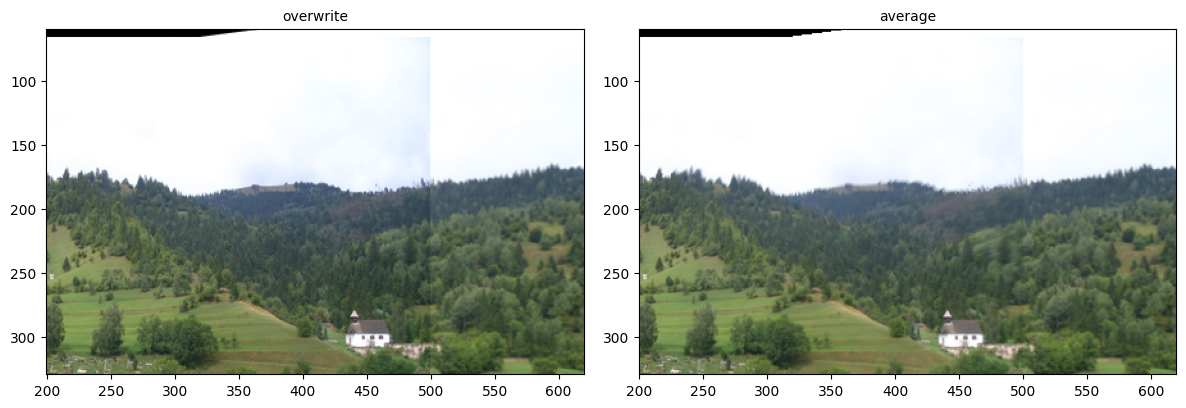

In [ ]:
x_from, x_to, y_from, y_to = 200, 620, 60, 330                # a window around the overlap, in canvas coordinates
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
for ax, (blend, pano) in zip(axes, panos.items()):
    ax.imshow(to_rgb(pano[y_from:y_to, x_from:x_to]), extent=(x_from - 0.5, x_to - 0.5, y_to - 0.5, y_from - 0.5))
    ax.set_title(blend, fontsize=10)
plt.tight_layout()
plt.show()

With **overwrite**, the border of the reference photo is a sharp vertical line at $x = 499$: `a.png` is brighter (its
green areas by about 15%) and its sky is whiter than the bluish sky of `b.png`. **Averaging** makes the jump smaller,
but it is still a line. (Blending cannot fix a bad alignment: if $H$ were off by a few pixels, averaging would show
**ghosting**, double edges in the overlap.)

**Interpolation flags.** In the previous class, `cv2.resize` with `cv2.INTER_AREA` was the remedy for aliasing when an
image is shrunk. Here the warp shrinks the left part of `a.png` a little (to about 0.85) and enlarges its right part up
to 1.7 times. We stitch with three flags and zoom into the right end of the panorama, where the enlargement is the
largest:

largest |INTER_AREA - INTER_LINEAR| difference: 0


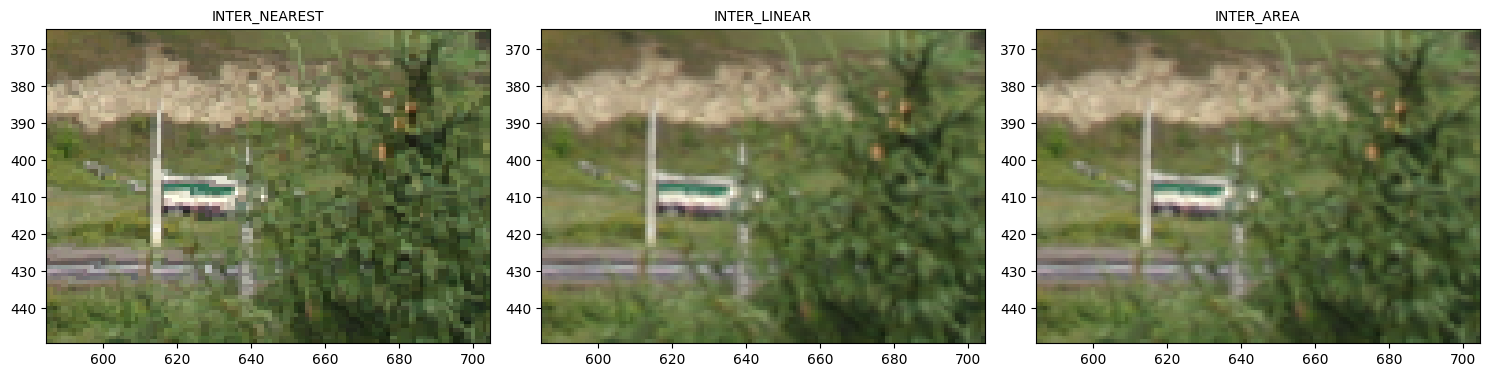

In [ ]:
interpolation_flags = {'INTER_NEAREST': cv2.INTER_NEAREST, 'INTER_LINEAR': cv2.INTER_LINEAR,
                       'INTER_AREA': cv2.INTER_AREA}
pano_flags = {name: stitch(img_left, img_right, H_manual, flags=flag)[0] for name, flag in interpolation_flags.items()}
print('largest |INTER_AREA - INTER_LINEAR| difference:',
      np.abs(pano_flags['INTER_AREA'].astype(int) - pano_flags['INTER_LINEAR']).max())

x_from, x_to, y_from, y_to = 585, 705, 365, 450               # the white vehicle and the poles, in canvas coordinates
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (name, pano) in zip(axes, pano_flags.items()):
    ax.imshow(to_rgb(pano[y_from:y_to, x_from:x_to]), extent=(x_from - 0.5, x_to - 0.5, y_to - 0.5, y_from - 0.5),
              interpolation='nearest')
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.show()


`INTER_NEAREST` turns the enlarged pixels into blocks (look at the poles). `INTER_AREA` gives **exactly** the same
panorama as `INTER_LINEAR`: OpenCV implements area averaging only in `cv2.resize`, and `cv2.warpAffine` and
`cv2.warpPerspective` silently replace `INTER_AREA` by `INTER_LINEAR`. For this panorama it does not matter, since
nothing is shrunk much. When a homography shrinks a part of an image strongly (e.g. the far end of a tilted plane,
Section 5), blur the image before warping it.

---

## 12. Automatic Correspondences: Feature Matching and RANSAC
Clicking correspondences by hand does not scale. Panorama software finds them automatically, in three steps.

### 12.1 Keypoints, descriptors and matching
1. **Keypoint detection and description.** We use SIFT (Lowe, 2004), available in OpenCV as `cv2.SIFT_create()`. It
   finds distinctive, blob-like points at several scales and describes the neighborhood of each with a 128-dimensional
   vector (histograms of gradient orientations) that barely changes if the image is rotated, scaled or brightened. We
   use it as a black box here.
2. **Matching.** For every keypoint of the right photo, we take the keypoint of the left photo with the most similar
   descriptor: the nearest neighbor in Euclidean distance. Many of these matches are wrong, since trees and grass look
   alike everywhere. **Lowe's ratio test** keeps a match only if its nearest neighbor is clearly better than the second
   nearest one, $d_1 < 0.75\,d_2$.
3. **Robust estimation** with RANSAC (Section 12.2), because even after the ratio test some matches are wrong, and a
   single wrong match can ruin a least-squares fit.

Since we already have a good homography from the hand-clicked points, we can use it to check how many matches are
correct (transfer error below 3 px):

In [ ]:
sift = cv2.SIFT_create()
kp_left, desc_left = sift.detectAndCompute(cv2.cvtColor(img_left, cv2.COLOR_BGR2GRAY), None)
kp_right, desc_right = sift.detectAndCompute(cv2.cvtColor(img_right, cv2.COLOR_BGR2GRAY), None)
print(f'SIFT keypoints: {len(kp_left)} in b.png, {len(kp_right)} in a.png;  descriptors: {desc_left.shape[1]}-dimensional')

# for every keypoint of the right photo: its 2 nearest neighbors among the descriptors of the left photo
knn = cv2.BFMatcher(cv2.NORM_L2).knnMatch(desc_right, desc_left, k=2)
src_all = np.array([kp_right[m.queryIdx].pt for m, _ in knn])          # (x, y) in the right photo
dst_all = np.array([kp_left[m.trainIdx].pt for m, _ in knn])           # (x, y) of the nearest neighbor in the left photo
passes_ratio = np.array([m.distance < 0.75 * n.distance for m, n in knn])
src, dst = src_all[passes_ratio], dst_all[passes_ratio]

for name, s, d in [('all nearest-neighbor matches', src_all, dst_all), ('after the ratio test', src, dst)]:
    correct = transfer_error(H_manual, s, d) < 3
    print(f'{name:>28}: {len(s):4d} matches, {correct.sum()} ({correct.mean():.0%}) of them agree with H_manual')

SIFT keypoints: 1272 in b.png, 1445 in a.png;  descriptors: 128-dimensional
all nearest-neighbor matches: 1445 matches, 394 (27%) of them agree with H_manual
        after the ratio test:  390 matches, 375 (96%) of them agree with H_manual


The ratio test throws away almost all wrong matches (all but 15 of 1051) and keeps almost all correct ones (375 of 394).

### 12.2 RANSAC for homographies
The recipe is the same as for lines in the RANSAC classes, only the model changes:

- **minimal sample:** 4 correspondences (a line needed 2 points), fitted exactly with `fit_homography`;
- **inliers:** the correspondences whose transfer error $\|\mathbf{x}'_i - H(\mathbf{x}_i)\|$ is below a threshold (3 px here);
- **adaptive number of iterations:** with an inlier ratio $w$, a sample of $s = 4$ correspondences contains only inliers
  with probability $w^4$, so $k = \lceil \ln(1 - p) / \ln(1 - w^4) \rceil$ iterations give confidence $p$
  (`iteration_number` from the RANSAC class);
- **final refit:** the normalized DLT on all inliers of the best sample, then we count the inliers of the refitted $H$.

Because the sample has 4 elements instead of 2, the number of iterations grows much faster as the inlier ratio drops:

In [ ]:
def iteration_number(confidence, sample_size, inliers, N):
    """Number of RANSAC iterations needed to draw at least one all-inlier sample with the given confidence."""
    if inliers == 0:
        return float('inf')
    ratio = inliers / float(N)
    if ratio == 1.0:                                           # every sample is all-inlier
        return 1
    top = math.log(1.0 - confidence)
    bottom = math.log(1.0 - ratio**sample_size)
    return math.ceil(top / bottom) if bottom != 0 else float('inf')


print('iterations for confidence p = 0.99:')
for w in [0.9, 0.5, 0.25, 0.1]:
    print(f'  inlier ratio {w:4.0%}:  line (s = 2) {iteration_number(0.99, 2, w * 100, 100):5d},'
          f'  homography (s = 4) {iteration_number(0.99, 4, w * 100, 100):5d}')

iterations for confidence p = 0.99:
  inlier ratio  90%:  line (s = 2)     3,  homography (s = 4)     5
  inlier ratio  50%:  line (s = 2)    17,  homography (s = 4)    72
  inlier ratio  25%:  line (s = 2)    72,  homography (s = 4)  1177
  inlier ratio  10%:  line (s = 2)   459,  homography (s = 4) 46050


In [ ]:
def ransac_homography(src, dst, threshold=3.0, confidence=0.99, max_iterations=10000, seed=0, verbose=True):
    """RANSAC for a homography dst ~ H src from (N, 2) arrays of putative correspondences.

    Returns the homography refitted on the inliers, the boolean inlier mask and the number of iterations.
    """
    rng = np.random.default_rng(seed)
    N = len(src)
    best_inliers = np.zeros(N, dtype=bool)
    it = 0
    while it < max_iterations:
        sample = rng.choice(N, 4, replace=False)
        with np.errstate(all='ignore'):                        # degenerate samples (3 collinear points) give useless H's
            H = fit_homography(src[sample], dst[sample])
            inliers = transfer_error(H, src, dst) < threshold  # NaN errors count as outliers
        if inliers.sum() > best_inliers.sum():
            best_inliers = inliers
            max_iterations = min(max_iterations, iteration_number(confidence, 4, inliers.sum(), N))
            if verbose:
                print(f'  iteration {it:4d}: {inliers.sum()} inliers ({inliers.mean():.0%}) -> max_iterations = {max_iterations}')
        it += 1

    H = fit_homography(src[best_inliers], dst[best_inliers])  # final refit on all inliers of the best sample
    return H, transfer_error(H, src, dst) < threshold, it


print('all nearest-neighbor matches:')
H_all, inliers_all, it = ransac_homography(src_all, dst_all)
print(f'  -> {it} iterations, {inliers_all.sum()} inliers after the refit\n')
print('after the ratio test:')
H_auto, inliers_auto, it = ransac_homography(src, dst)
print(f'  -> {it} iterations, {inliers_auto.sum()} inliers of {len(src)} after the refit\n')
print('largest distance between H_all(x) and H_auto(x) over the inliers:',
      f'{np.max(np.linalg.norm(transform_points(H_all, src[inliers_auto]) - transform_points(H_auto, src[inliers_auto]), axis=1)):.3f} px')

all nearest-neighbor matches:
  iteration    0: 5 inliers (0%) -> max_iterations = 10000
  iteration    1: 7 inliers (0%) -> max_iterations = 10000
  iteration   23: 11 inliers (1%) -> max_iterations = 10000
  iteration   36: 30 inliers (2%) -> max_iterations = 10000
  iteration   43: 277 inliers (19%) -> max_iterations = 3409
  iteration  153: 393 inliers (27%) -> max_iterations = 840
  -> 840 iterations, 394 inliers after the refit

after the ratio test:
  iteration    0: 310 inliers (79%) -> max_iterations = 10
  iteration    7: 343 inliers (88%) -> max_iterations = 6
  -> 8 iterations, 374 inliers of 390 after the refit

largest distance between H_all(x) and H_auto(x) over the inliers: 1.602 px


Without the ratio test, only about a quarter of the matches are inliers, and RANSAC needs hundreds of iterations.
After the ratio test, over 90% are inliers, and a handful of iterations is enough. The two homographies differ by less
than 2 px on the inliers, within the 3 px threshold.

Now we compare with `cv2.findHomography` with `cv2.RANSAC` and the same threshold, and check how well the automatic
homography explains the 8 hand-clicked correspondences, which it has never seen:

inliers: ours 374, OpenCV 373, both 373 (of 390 matches)
      ours (H_auto): RMS transfer error on the common inliers 0.787 px, on the 8 hand-clicked pairs 1.397 px
 cv2.findHomography: RMS transfer error on the common inliers 0.700 px, on the 8 hand-clicked pairs 1.425 px


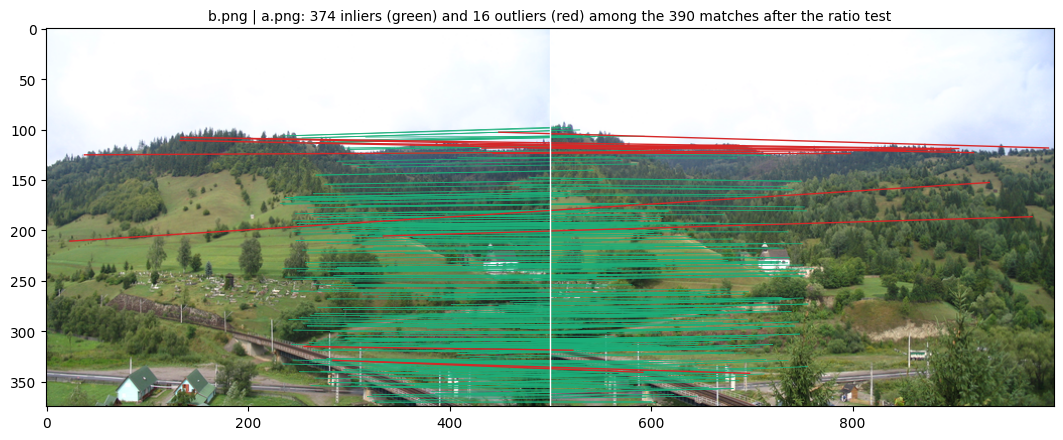

In [ ]:
H_cv_ransac, mask = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
mask = mask.ravel().astype(bool)
print(f'inliers: ours {inliers_auto.sum()}, OpenCV {mask.sum()}, both {np.sum(inliers_auto & mask)} (of {len(src)} matches)')
for name, H in [('ours (H_auto)', H_auto), ('cv2.findHomography', H_cv_ransac)]:
    e_in = transfer_error(H, src[inliers_auto & mask], dst[inliers_auto & mask])
    e_manual = transfer_error(H, pts_right, pts_left)
    print(f'{name:>19}: RMS transfer error on the common inliers {np.sqrt(np.mean(e_in**2)):.3f} px,'
          f' on the 8 hand-clicked pairs {np.sqrt(np.mean(e_manual**2)):.3f} px')

fig, ax = plt.subplots(figsize=(13, 5))
ax.imshow(to_rgb(np.hstack([img_left, img_right])))
offset = img_left.shape[1]
for is_inlier, color, lw in [(True, '#1baf7a', 0.6), (False, '#d62728', 1.0)]:
    for p, q in zip(dst[inliers_auto == is_inlier], src[inliers_auto == is_inlier]):
        ax.plot([p[0], q[0] + offset], [p[1], q[1]], color=color, lw=lw)
ax.axvline(offset - 0.5, color='white', lw=1)
ax.set_title(f'b.png | a.png: {inliers_auto.sum()} inliers (green) and {np.sum(~inliers_auto)} outliers (red) '
             f'among the {len(src)} matches after the ratio test', fontsize=10)
plt.show()

Every inlier of OpenCV is an inlier of ours too. OpenCV reports the inliers of its best 4-point sample, while we
count them again after the refit, which adds the matches that were just above the threshold. On the common inliers
both transfer errors are below a pixel; OpenCV's is lower, because after RANSAC it refines $H$ by minimizing the
transfer error (as with `method=0` in Section 10). On the 8 hand-clicked pairs, which neither of them has seen, the
error is about 1.4 px, only a little more than for $H_{manual}$ (1.15 px), which was fitted to exactly these points.
So the automatic homography agrees with the hand-clicked points within the accuracy of the clicking. Most outliers
are matches on repetitive texture (the forest on the ridge) and matches from the right part of `a.png`, which `b.png`
does not show at all.

### 12.3 The final panorama
The panorama with $H_{auto}$ and averaging, and for comparison OpenCV's complete pipeline, `cv2.Stitcher`. Besides
matching and RANSAC, it estimates the focal length and the rotation of the camera ($H = KRK^{-1}$ from Section 8) and
refines them with bundle adjustment, projects the photos onto a sphere instead of a plane, compensates exposure
differences, finds a seam through the overlap and blends with multi-band blending.

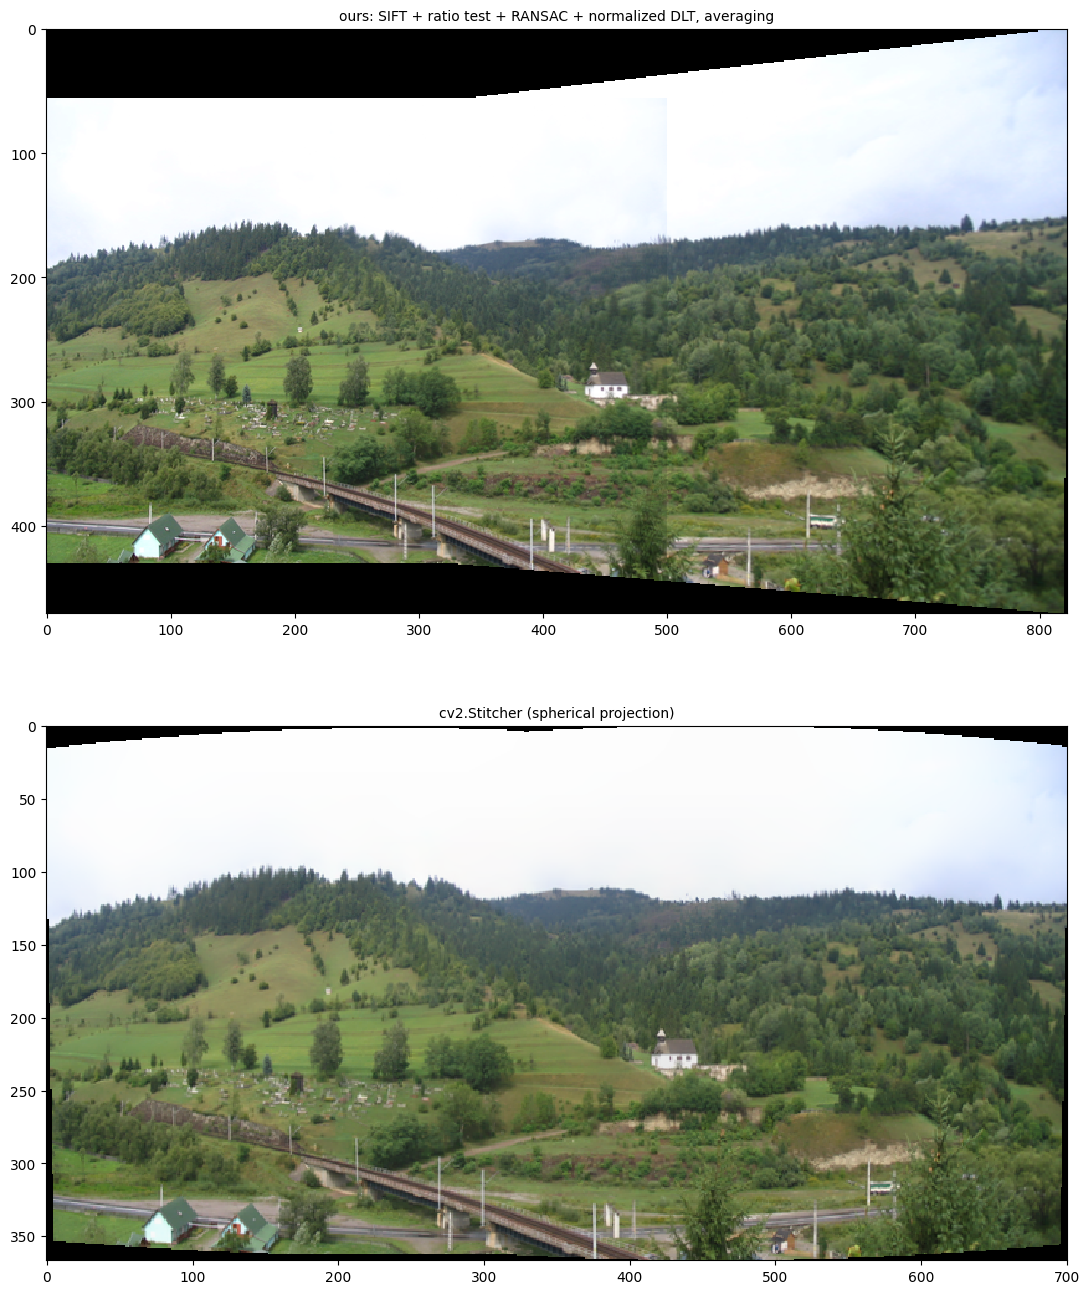

In [ ]:
pano_auto, _ = stitch(img_left, img_right, H_auto)
status, pano_cv = cv2.Stitcher_create(cv2.Stitcher_PANORAMA).stitch([img_left, img_right])
if status == cv2.Stitcher_OK:
    show_images([pano_auto, pano_cv], ['ours: SIFT + ratio test + RANSAC + normalized DLT, averaging',
                                       'cv2.Stitcher (spherical projection)'], cols=1, size=11)
else:
    print('cv2.Stitcher failed with status', status)
    show_images([pano_auto], ['ours: SIFT + ratio test + RANSAC + normalized DLT, averaging'], size=11)

---
## 13. Summary

The hierarchy of 2D transformations. Each class contains the classes above it, and a transformation
preserves the properties in its own row and in all rows below it:

| transformation | upper-left $2 \times 2$ block | last row | DOF | additionally preserves |
|---|---|---|---|---|
| Euclidean (rigid) | rotation $R$ | $[0 \;\, 0 \;\, 1]$ | 3 | lengths, areas |
| similarity | $sR$ | $[0 \;\, 0 \;\, 1]$ | 4 | angles, ratios of lengths |
| affine | any invertible $A$ | $[0 \;\, 0 \;\, 1]$ | 6 | parallelism, ratios of lengths along a line, ratios of areas |
| projective (homography) | anything (with $H$ invertible) | $[h_{31} \;\, h_{32} \;\, h_{33}]$ | 8 | straight lines, incidence, cross-ratio |

Key takeaways:
- **Changing the last row** makes the third coordinate $w = h_{31}x + h_{32}y + h_{33}$ vary across the image,
  and dividing by it (the **perspective division**) creates perspective. $H$ and $\lambda H$ describe the same
  transformation, so a homography has 8 degrees of freedom.
- Straight lines stay straight, but **parallel lines meet at vanishing points**: the point at infinity
  $(d_x, d_y, 0)$ is mapped to a finite point as soon as $h_{31}d_x + h_{32}d_y \neq 0$. All vanishing points lie
  on the **horizon**, the image $H^{-\top}\mathbf{l}_\infty$ of the line at infinity. Ratios of lengths (midpoints)
  are not preserved.
- The local magnification ($\det H / w^3$) changes across the image, so forward mapping produces holes and
  collisions in different parts of the same image. Backward mapping works unchanged.
- For a camera looking at a plane, $H = K[\mathbf{r}_1 \;\, \mathbf{r}_2 \;\, \mathbf{t}]$ and $w$ is the **depth**:
  the perspective division is the division by depth.
- OpenCV: `cv2.warpPerspective` (full $3 \times 3$ matrix, backward mapping), `cv2.getPerspectiveTransform`
  (exactly 4 point pairs), `cv2.findHomography` (many pairs, with RANSAC), `cv2.perspectiveTransform` (for
  points). `cv2.warpAffine` silently ignores the last row, and both warps silently replace `INTER_AREA` by
  `INTER_LINEAR`.

From two photos to a panorama:
- Two photos are related by a homography if the scene is a **plane** ($H = H_2 H_1^{-1}$) or if the camera only
  **rotates about its projection center** ($H = KRK^{-1}$, for any scene). If the projection center moves, points
  at different depths move differently (**parallax**, about $f\,|\mathbf{c}| / Z_c$ pixels).
- **DLT:** every correspondence gives 2 equations that are linear in the 9 entries of $H$. We solve $A\mathbf{h} = \mathbf{0}$
  with $\|\mathbf{h}\| = 1$ by the SVD: $\mathbf{h}$ is the last row of $V^\top$. 4 correspondences determine $H$; with
  more, the DLT minimizes the algebraic error $\|A\mathbf{h}\|$.
- **Normalize first:** move the centroid of the points of each image to the origin and scale their mean distance to
  $\sqrt{2}$, run the DLT, then denormalize: $H = T'^{-1}\tilde{H}T$. Without it, the result depends on the choice of
  the coordinate system, and the $A^\top A$ route can break down.
- **Panorama:** choose a reference photo, map the corners of the other photo to find the canvas, warp with $TH$ and
  blend. Overwriting leaves a seam where the reference photo ends and averaging only weakens it; weights that fade out
  towards the borders of each photo (**feathering**, Exercise 6) remove it.
- **Automatic correspondences:** SIFT keypoints, nearest-neighbor matching with the ratio test, and **RANSAC** with
  4-point samples, the transfer error and an adaptive number of iterations, followed by a refit on all inliers.
  `cv2.findHomography(src, dst, cv2.RANSAC, threshold)` does the same (and refines $H$ by minimizing the transfer
  error), `cv2.Stitcher` runs a complete panorama pipeline.

### Exercises
1. Make the line $w = 0$ (the line that is mapped to infinity) cross the image, e.g. with the last row
   $[-0.006, 0, 1]$. What happens to the pixels beyond this line in `forward_warp`, in `backward_warp` and
   in `cv2.warpPerspective`? What would they correspond to for the camera of Section 5?
2. The DLT of Section 9 fixes the scale of $H$ with $\|\mathbf{h}\| = 1$. Another option is to fix $h_{33} = 1$.
   Multiplying $x' = \frac{h_{11}x + h_{12}y + h_{13}}{h_{31}x + h_{32}y + 1}$ by the denominator gives an equation
   that is **linear** in the 8 remaining unknowns: $h_{11}x + h_{12}y + h_{13} - h_{31}x x' - h_{32}y x' = x'$, and
   similarly for $y'$. For 4 point pairs, set up the $8 \times 8$ system (as we did for `getAffineTransform` in the
   previous class), solve it with `np.linalg.solve` and `cv2.solve`, and compare the result with
   `fit_homography_dlt` and `cv2.getPerspectiveTransform`. Which homographies cannot be found this way?
3. Photograph a document or a book cover at an angle, read off the pixel coordinates of its 4 corners
   (e.g. from a Matplotlib plot), and rectify it with `cv2.getPerspectiveTransform` and
   `cv2.warpPerspective`. Choose the output size from the real aspect ratio of the object (A4 paper:
   $1 : \sqrt{2}$).
4. Estimate the focal length and the rotation of the camera from the panorama homography. For a rotating camera
   $H \simeq KRK^{-1}$ (Section 8). Assume square pixels and the principal point at the image center,
   $K = \begin{bmatrix} f & 0 & c_x \\ 0 & f & c_y \\ 0 & 0 & 1 \end{bmatrix}$. For a range of $f$ values, compute
   $M = K^{-1}HK$, scale it so that $\det M = 1$, and measure how far it is from a rotation, e.g. with
   $\|M^\top M - I\|$. Which $f$ fits best? What is the rotation angle between the two photos, and about which axis?
5. Take your own photos with a phone: once turning the phone about its lens, once stepping half a meter sideways
   between the shots, with some objects close to the camera. Stitch both pairs with the pipeline of Section 12.
   Where do you see ghosting, and why?
6. **Feathering.** Averaging leaves a seam where the reference photo ends (Section 11), because the weights of the two
   photos jump from $(1, 0)$ to $(\frac{1}{2}, \frac{1}{2})$ there. Feathering lets every photo fade out towards its
   borders: photo $k$ gets a weight map $\alpha_k$, the distance of each pixel from the border of the photo,
   $\alpha(x, y) = \min(x + 1,\; \mathrm{width} - x,\; y + 1,\; \mathrm{height} - y)$ (1 at the outermost pixels, largest
   at the center). The panorama is the weighted average $\sum_k \mathrm{warp}(\alpha_k I_k) \,/\, \sum_k \mathrm{warp}(\alpha_k)$:
   warp the weighted photo $\alpha_k I_k$ and the weight map $\alpha_k$ with the same matrix ($T$ or $TH$). Write a
   vectorized `border_distance(h, w)` that returns $\alpha$ (e.g. with `np.mgrid`) and add `blend='feather'` to
   `stitch`; the `'average'` branch is the special case $\alpha_k = 1$. Compare the three blending methods in the
   overlap window of Section 11: the seam at $x = 499$ should disappear.